In [1]:
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow
import numpy as np
import math
import datetime

from scipy import signal
from scipy.optimize import curve_fit
from scipy import stats
from scipy.stats import t as t_dist
import matplotlib.pyplot as plt
import matplotlib.ticker as ptick
import matplotlib.colors as mplcolors
from matplotlib.ticker import FixedLocator
from matplotlib.ticker import AutoMinorLocator
import matplotlib.dates as mdates
from matplotlib.patches import FancyArrowPatch, Rectangle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

from CSField import CSField
import JupiterMag as jm

jm.Internal.Config(Model='jrm33', CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

Importing Library
done


In [2]:
def day2hhmm(decimal_day):
    doy = int(decimal_day)
    rest = decimal_day - doy

    hours = int(rest*24)
    minutes = (rest*24-hours)*60

    if round(minutes) >= 60:
        hours += 1
        minutes = 0
    else:
        minutes = round(minutes)
    return hours, minutes


def hhmm2day(hours, minutes, seconds=0):
    fraction_of_day = hours/24 + minutes/(60*24) + seconds/(60*60*24)
    return fraction_of_day


def fmt_hhmm(decimal_day):
    hours, minutes = day2hhmm(decimal_day)
    hh = '{:02}'.format(hours)
    mm = '{:02}'.format(minutes)
    return hh+':'+mm

In [3]:
# Data from Connerney+2020: PJ index
con20_pj_idx = np.array([1, 3, 4, 5, 6,
                        7, 8, 9, 10, 11,
                        12, 13, 14, 15, 16,
                        17, 18, 19, 20, 21,
                        22, 23, 24], dtype=int)

# Data from Connerney+2020: Current constant [nT]
con20_mu_i_tot = np.array([150.1, 137.8, 127.2, 129.1, 130.1,
                           142.3, 140.1, 143.8, 137.0, 141.4,
                           124.2, 148.9, 145.3, 144.8, 149.9,
                           132.1, 133.5, 152.9, 138.5, 138.8,
                           156.1, 141.4, 146.3])

# Data from Connerney+2020: Radial current constant [MA]
con20_mu_i_rho = np.array([35.2, 14.6, 7.7, 11.5, 20.8,
                           20.2, 12.2, 21.1, 20.9, 10.7,
                           26.26, 16.4, 12.0, 19.6, 12.0,
                           13.6, 20.0, 12.8, 16.0, 17.3,
                           9.9, 16.1, 10.3])

In [4]:
# 定数
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492.0E+3          # JUPITER RADIUS [m]

# Angular velocity of Jupiter System III rotation [rad sec-1]
OMG_J = 2*np.pi/(9.55*3600)
OMG_G = 2*np.pi/(7.2*24*3600)   # Ganymede orbital angular velosity [rad/sec]

In [5]:
PJ_list = [1, 3, 4, 5,
           6, 7, 8, 9, 10,
           11, 12, 13, 14, 15,
           16, 17, 18, 19, 20,
           21, 22, 23, 24, 25,
           26, 27, 28, 29, 30,
           31, 32, 33, 34, 35,
           36, 37, 38, 39, 40,
           41, 42, 43, 44, 45,
           46, 47, 48, 49, 50,
           51, 52, 53, 54, 55,
           56, 57, 58, 59, 60,
           61, 62, 63, 64, 65,
           66, 67, 68, 69, 70,
           71, 72, 73, 74, 75,
           76, 77, 78, 79, 80]
dir = 'results/insitu_fit_a0_a1_b4_v2_36rj'
f0 = np.loadtxt(dir+'/result_PJ' +
                str(PJ_list[0]).zfill(2)+'_PJ'+str(PJ_list[-1]).zfill(2)+'.txt')
case = 'Case II'
linecolor = UC.pink

In [6]:
# %% Juno's perijove times
JUNO_PJ_TIMES = [
    datetime.datetime.strptime(
        '2016-08-27 12:50', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2016-10-19 18:10', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2016-12-11 17:03', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-02-02 12:57', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-03-27 08:51', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-05-19 06:00', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-07-11 01:54', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-09-01 21:48', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-10-24 17:42', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2017-12-16 17:56', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-02-07 13:51', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-04-01 09:45', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-05-24 05:39', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-07-16 05:17', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-09-07 01:11', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-10-29 21:05', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2018-12-21 16:59', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-02-12 17:34', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-04-06 12:14', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-05-29 08:08', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-07-21 04:02', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-09-12 03:40', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-11-03 22:18', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2019-12-26 17:36', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-02-17 17:51', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-04-10 13:47', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-06-02 10:20', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-07-25 06:15', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-09-16 02:10', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-11-08 01:49', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2020-12-30 21:45', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-02-21 17:40', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-04-15 23:32', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-06-08 07:46', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-07-21 08:15', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-09-02 22:42', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-10-16 17:13', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2021-11-29 14:13', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-01-12 10:33', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-02-25 01:59', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-04-09 15:49', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-05-23 02:15', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-07-05 09:17', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-08-17 14:45', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2022-09-29 17:11', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime('2022-11-06', '%Y-%m-%d'),  # PJ46
    datetime.datetime.strptime('2022-12-15', '%Y-%m-%d'),  # PJ47
    datetime.datetime.strptime('2023-01-22', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-03-01', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-04-08', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-05-16', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-06-23', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-07-31', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-09-07', '%Y-%m-%d'),  # PJ54
    datetime.datetime.strptime('2023-10-15', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-11-22', '%Y-%m-%d'),
    datetime.datetime.strptime('2023-12-30', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-02-04', '%Y-%m-%d'),  # PJ58
    datetime.datetime.strptime('2024-03-07', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-04-09', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-05-12', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-06-14', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-07-16', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-08-18', '%Y-%m-%d'),  # PJ64
    datetime.datetime.strptime('2024-09-20', '%Y-%m-%d'),
    datetime.datetime.strptime('2024-10-22', '%Y-%m-%d'),  # PJ66
    datetime.datetime.strptime(
        '2024-11-24 13:05', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2024-12-27 05:22', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-01-28 23:05', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-03-02 16:04', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-04-04 09:30', '%Y-%m-%d %H:%M'),             # PJ71
    datetime.datetime.strptime(
        '2025-05-07 03:01', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-06-08 20:30', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-07-11 13:40', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-08-13 07:04', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-09-14 23:52', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-10-17 16:04', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-11-19 08:37', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2025-12-22 01:14', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2026-01-23 17:17', '%Y-%m-%d %H:%M'),
    datetime.datetime.strptime(
        '2026-02-25 09:32', '%Y-%m-%d %H:%M'),
]
JUNO_PJ_LABELS = ['PJ1', '', '', '', '',
                  '6', '', '', '', '',
                  '11', '', '', '', '',
                  '16', '', '', '', '',
                  '21', '', '', '', '',
                  '26', '', '', '', '',
                  '31', '', '', '', '',
                  '36', '', '', '', '',
                  '41', '', '', '', '',
                  '46', '', '', '', '',
                  '51', '', '', '', '',
                  '56', '', '', '', '',
                  '61', '', '', '', '',
                  '66', '', '', '', '',
                  '71', '', '', '', '',
                  '76', '', '', '', '',
                  '81',]

In [7]:
print(len(JUNO_PJ_TIMES))

81


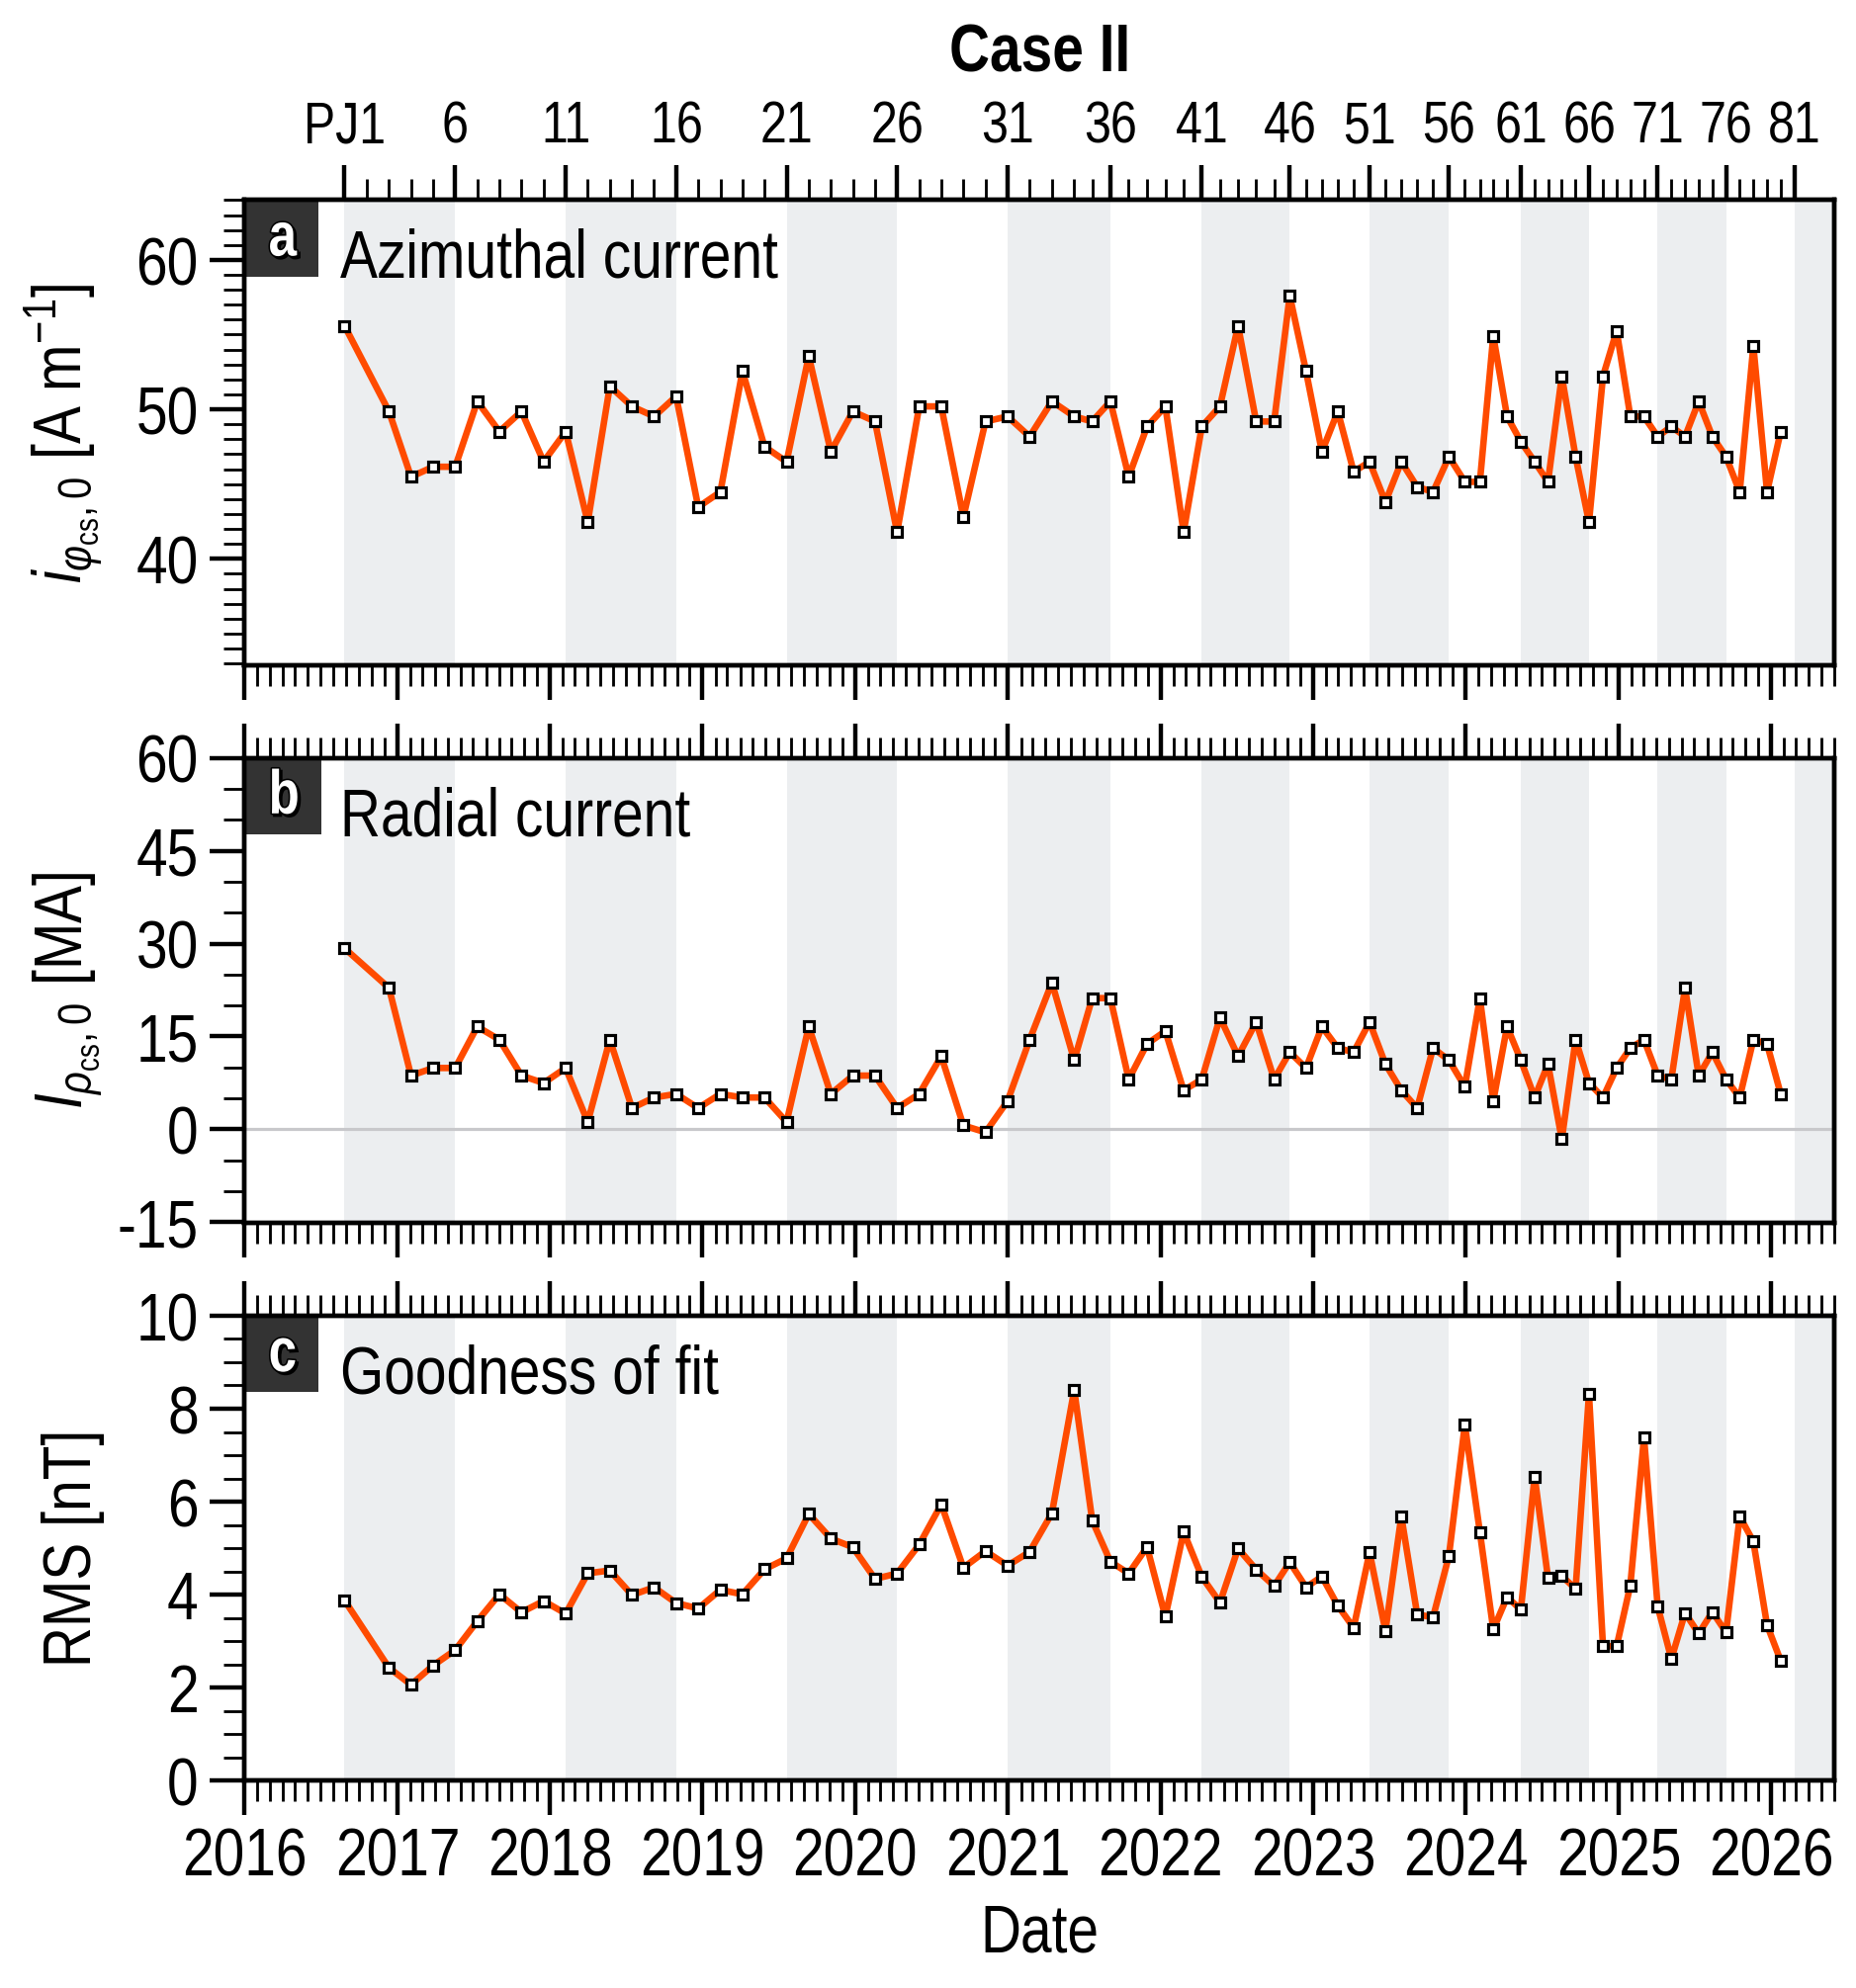

Mean & standard deviation (all)
i_phi [A m-1]: 48.45093370096503 3.3312443659715822
I_rho [MA]: 10.45591036962724 6.0256512071160016
RMS [nT]: 4.374311679391941 1.214822923066515
Mean & standard deviation (first 40 perijoves)
i_phi [A m-1]: 48.307692307692314 3.1251754569494645
I_rho [MA]: 9.98201490088417 6.909470115792443
RMS [nT]: 4.4079356788458375 1.1062283340231645


In [8]:
# %% ================================
# 横軸: date / 縦軸: 電流の沿磁力線積分値
# ===================================
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=3, figsize=(8.3, 8.3), ticksize=1.5, dpi='L')
F.hspace = 0.2
F.initialize()

sxmin = '2016-01-01'
sxmax = '2026-06-01'
xmin = datetime.datetime.strptime(sxmin, '%Y-%m-%d')
xmax = datetime.datetime.strptime(sxmax, '%Y-%m-%d')
xticks = [datetime.datetime.strptime('2016-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2017-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2018-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2019-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2020-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2021-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2022-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2023-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2024-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2025-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2026-01-01', '%Y-%m-%d')]
xticklabels = ['2016', '2017', '2018', '2019', '2020',
               '2021', '2022', '2023', '2024', '2025',
               '2026']
F.set_xaxis(label='Date',
            min=xmin, max=xmax,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=12,
            format='%Y-%m-%d')
ticklabels = F.ax[2].get_xticklabels()
ticklabels[0].set_ha('center')
F.set_yaxis(ax_idx=0,
            label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=32.9, max=64.0,
            ticks=np.arange(40, 60+1, 10),
            ticklabels=np.arange(40, 60+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-15.1, max=60,
            ticks=np.arange(-15, 60+1, 15),
            ticklabels=np.arange(-15, 60+1, 15),
            minor_num=3,)
F.set_yaxis(ax_idx=2,
            label=r'RMS [nT]',
            min=0.0, max=10,
            ticks=np.arange(0, 10+1, 2),
            ticklabels=np.arange(0, 10+1, 2),
            minor_num=4,)

# Azimuthal current
pj_2_date = []
for i in range(f0[:, 0].size):
    pj_2_date += [JUNO_PJ_TIMES[int(f0[i, 0])-1]]
F.ax[0].plot(pj_2_date, f0[:, 1]*1E+6,
             marker='s', color=UC.red, markersize=3,
             linewidth=2.1, markeredgecolor='k', markerfacecolor='w',
             zorder=2)

# Radial current
F.ax[1].plot(pj_2_date, f0[:, 3],
             marker='s', color=UC.red, markersize=3,
             linewidth=2.1, markeredgecolor='k', markerfacecolor='w',
             zorder=2)

# RMS
F.ax[2].plot(pj_2_date, f0[:, 5],
             marker='s', color=UC.red, markersize=3,
             linewidth=2.1, markeredgecolor='k', markerfacecolor='w',
             zorder=2)

# PJ numbers on the top horizontal axis
PJax = F.ax[0].twiny()
PJax.set_xlim(xmin, xmax)
PJax.set_xticks(JUNO_PJ_TIMES[::5])
PJax.set_xticklabels(JUNO_PJ_LABELS[::5], fontsize=F.fontsize*0.85)
PJax.xaxis.set_minor_locator(FixedLocator(mdates.date2num(JUNO_PJ_TIMES)))
PJax.tick_params('y', grid_zorder=-10)
PJax.set_title(case, weight='bold')

# Shades in each 5 perijove
for i in range(3):
    F.ax[i].axvspan(JUNO_PJ_TIMES[0], JUNO_PJ_TIMES[5],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[10], JUNO_PJ_TIMES[15],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[20], JUNO_PJ_TIMES[25],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[30], JUNO_PJ_TIMES[35],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[40], JUNO_PJ_TIMES[45],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[50], JUNO_PJ_TIMES[55],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[60], JUNO_PJ_TIMES[65],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[70], JUNO_PJ_TIMES[75],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[80], xmax,
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)

F.ax[1].axhline(y=0, color=UC.lightgray, linewidth=1.0, zorder=0.9)

F.ax[0].text(0.06, 0.94,
             'Azimuthal current',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[1].text(0.06, 0.94,
             'Radial current',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[1].transAxes)
F.ax[2].text(0.06, 0.94,
             'Goodness of fit',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[2].transAxes)

"""legend = F.legend(ax_idx=0,
                  ncol=2, markerscale=1.0,
                  loc='lower center',
                  handlelength=0.85,
                  textcolor=False,
                  fontsize_scale=0.65,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[0], d=0.7)"""

plt.savefig('img/'+dir[8:]+'_time_001.pdf',
            bbox_inches='tight')
plt.show()
F.close()
plt.close()

print('Mean & standard deviation (all)')
print('i_phi [A m-1]:', np.mean(f0[:, 1]*1E+6), np.std(f0[:, 1]*1E+6))
print('I_rho [MA]:', np.mean(f0[:, 3]), np.std(f0[:, 3]))
print('RMS [nT]:', np.mean(f0[:, 5]), np.std(f0[:, 5]))

print('Mean & standard deviation (first 40 perijoves)')
print('i_phi [A m-1]:', np.mean(f0[0:39, 1]*1E+6), np.std(f0[0:39, 1]*1E+6))
print('I_rho [MA]:', np.mean(f0[0:39, 3]), np.std(f0[0:39, 3]))
print('RMS [nT]:', np.mean(f0[0:39, 5]), np.std(f0[0:39, 5]))

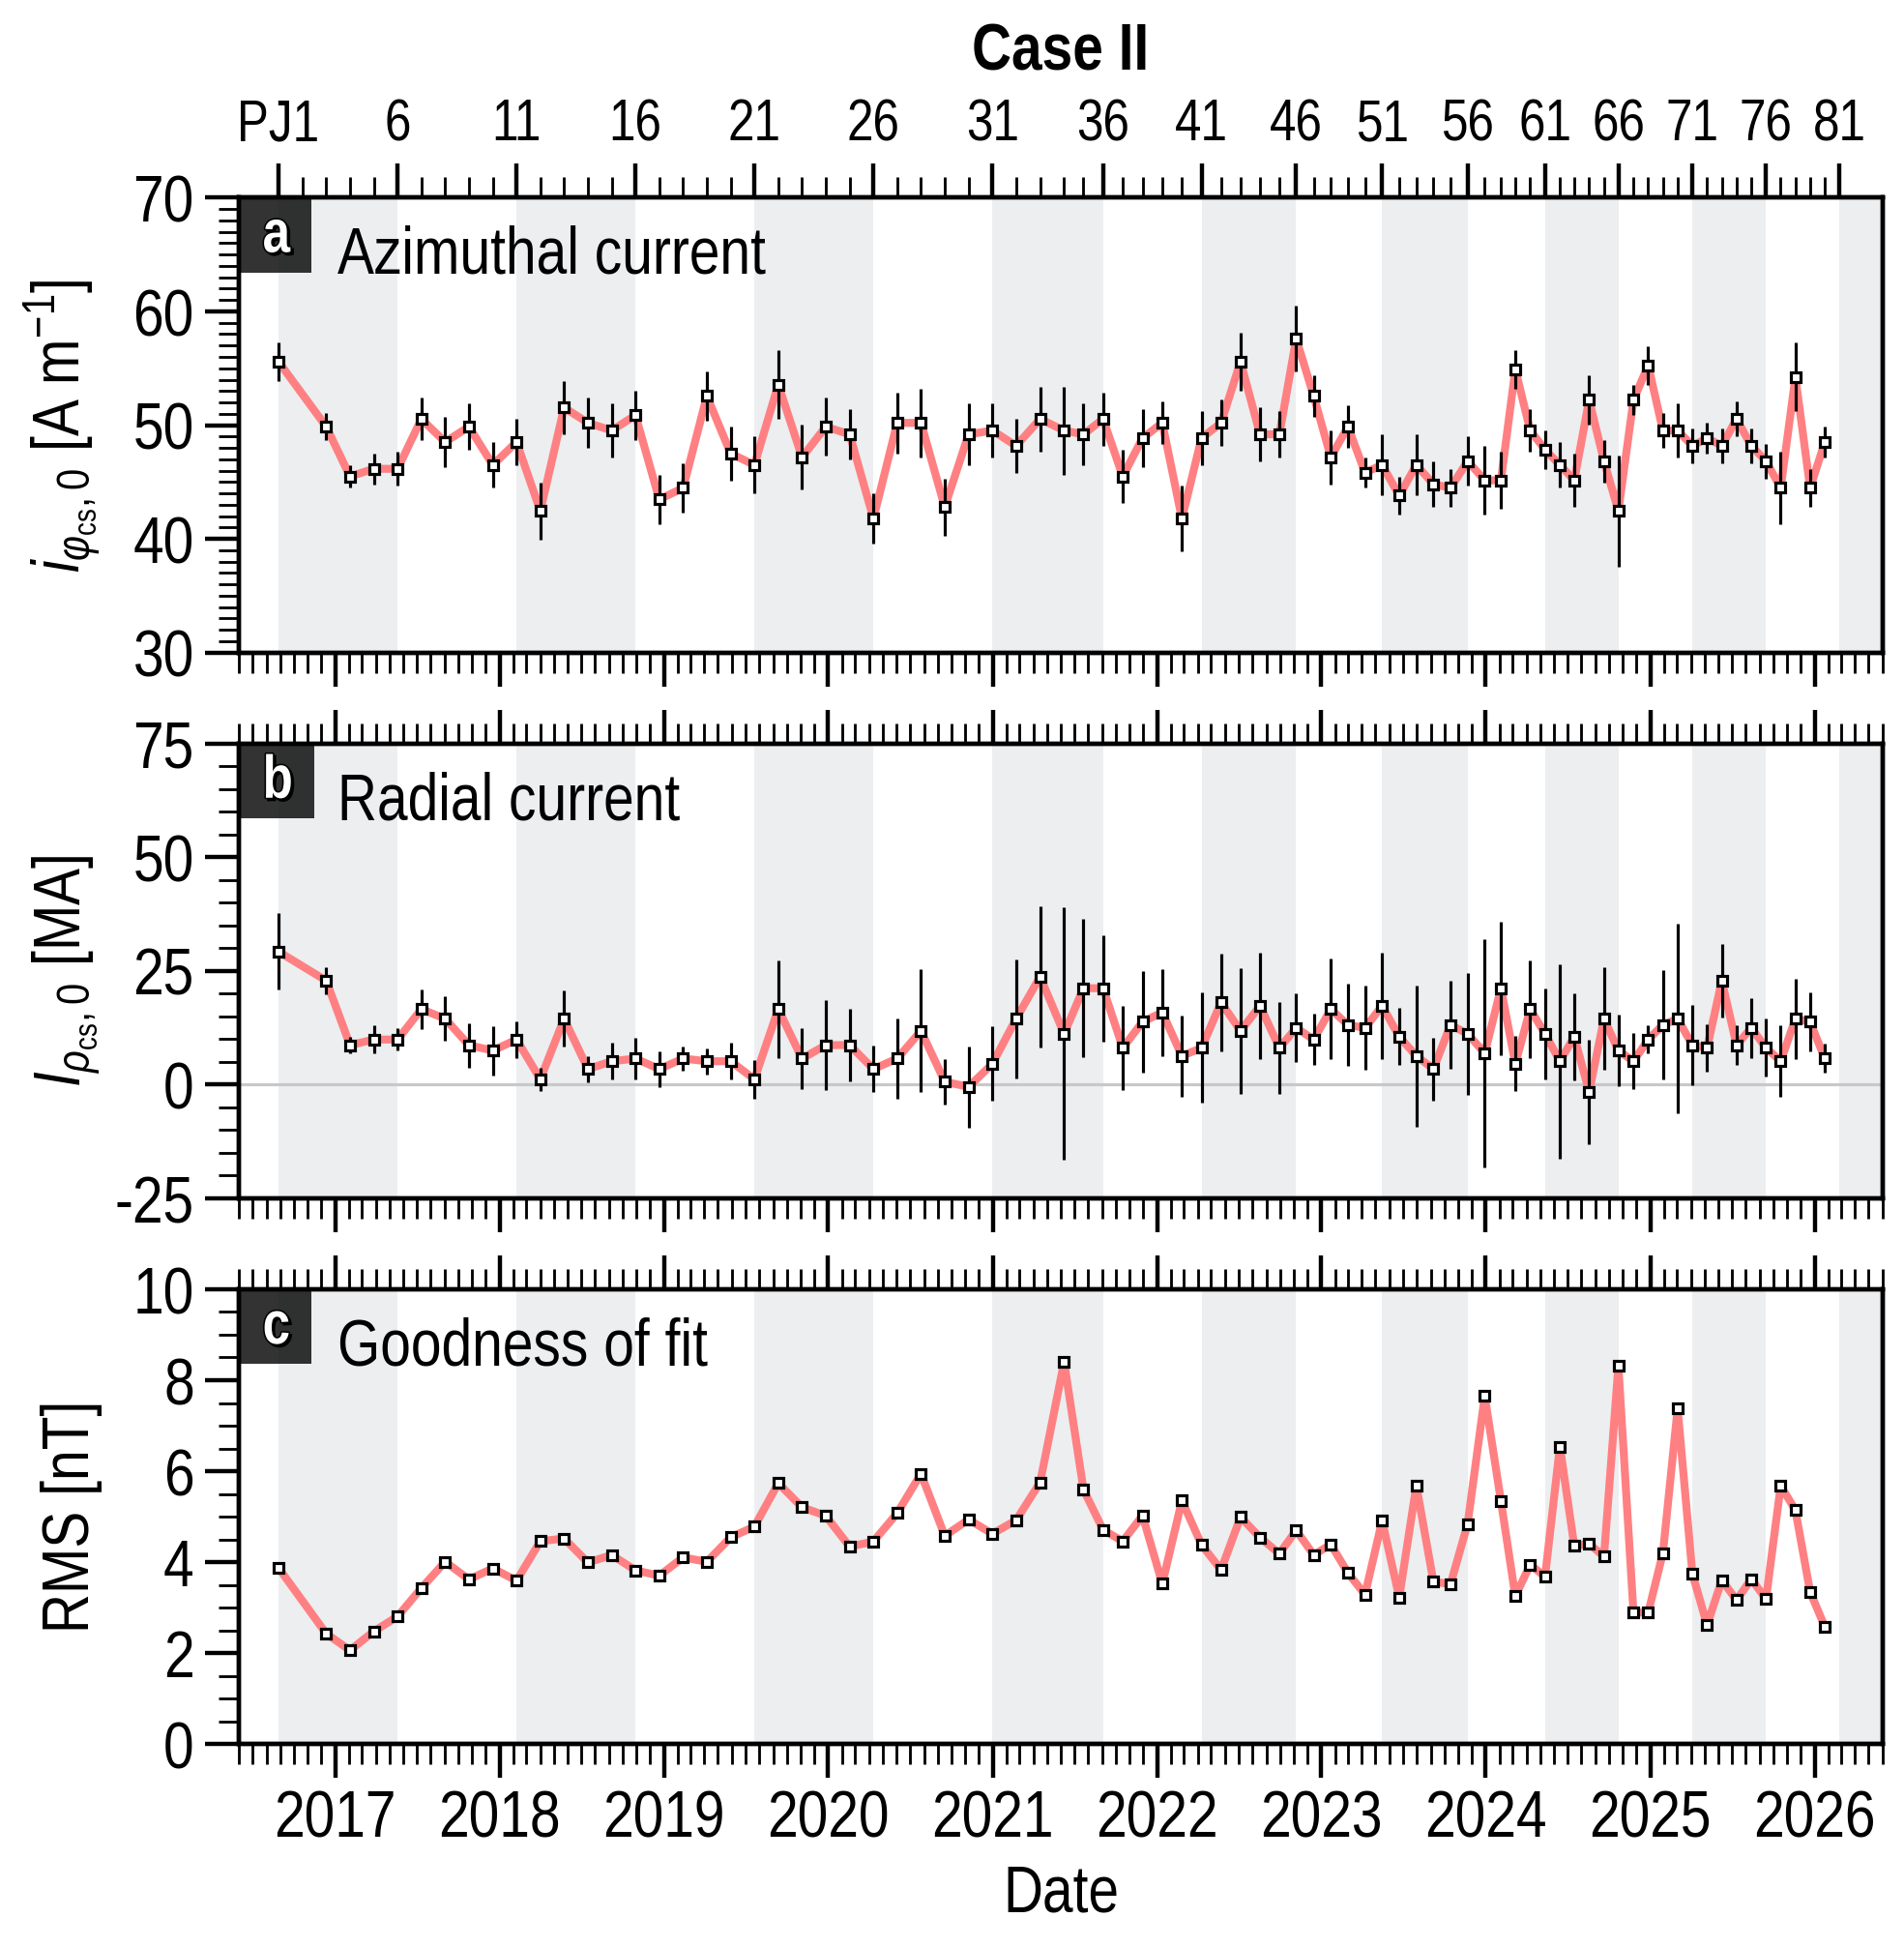

In [9]:
# %% ================================
# 横軸: date / 縦軸: 電流の沿磁力線積分値
# ===================================
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=3, figsize=(8.7, 8.3), ticksize=1.5, dpi='L')
F.hspace = 0.2
F.initialize()

sxmin = '2016-06-01'
sxmax = '2026-06-01'
xmin = datetime.datetime.strptime(sxmin, '%Y-%m-%d')
xmax = datetime.datetime.strptime(sxmax, '%Y-%m-%d')
xticks = [datetime.datetime.strptime('2017-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2018-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2019-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2020-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2021-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2022-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2023-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2024-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2025-01-01', '%Y-%m-%d'),
          datetime.datetime.strptime('2026-01-01', '%Y-%m-%d')]
xticklabels = ['2017', '2018', '2019', '2020',
               '2021', '2022', '2023', '2024', '2025',
               '2026']
F.set_xaxis(label='Date',
            min=xmin, max=xmax,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=12,
            format='%Y-%m-%d')
ticklabels = F.ax[2].get_xticklabels()
ticklabels[0].set_ha('center')
F.set_yaxis(ax_idx=0,
            label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=75,
            ticks=np.arange(-25, 75+1, 25),
            ticklabels=np.arange(-25, 75+1, 25),
            minor_num=5,)
F.set_yaxis(ax_idx=2,
            label=r'RMS [nT]',
            min=0.0, max=10,
            ticks=np.arange(0, 10+1, 2),
            ticklabels=np.arange(0, 10+1, 2),
            minor_num=4,)

# Azimuthal current
pj_2_date = []
for i in range(f0[:, 0].size):
    pj_2_date += [JUNO_PJ_TIMES[int(f0[i, 0])-1]]
F.ax[0].plot(pj_2_date, f0[:, 1]*1E+6,
             marker='s', color=linecolor, markersize=0,
             linewidth=2.6, markeredgecolor='k', markerfacecolor='w',
             zorder=3)
F.ax[0].errorbar(x=pj_2_date, y=f0[:, 1]*1E+6,
                 yerr=f0[:, 2]*1E+6, color='k',
                 elinewidth=1.0, linewidth=0.,
                 marker='s', markersize=3.3,
                 markeredgecolor='k', markerfacecolor='w',
                 markeredgewidth=1.,
                 zorder=4)

# Radial current
F.ax[1].plot(pj_2_date, f0[:, 3],
             marker='s', color=linecolor, markersize=0,
             linewidth=2.6, markeredgecolor='k', markerfacecolor='w',
             zorder=2)
F.ax[1].errorbar(x=pj_2_date, y=f0[:, 3],
                 yerr=f0[:, 4], color='k',
                 elinewidth=1.0, linewidth=0.,
                 marker='s', markersize=3.3,
                 markeredgecolor='k', markerfacecolor='w',
                 markeredgewidth=1.,
                 zorder=4)

# RMS
F.ax[2].plot(pj_2_date, f0[:, 5],
             marker='s', color=linecolor, markersize=3.3,
             linewidth=2.6, markeredgecolor='k', markerfacecolor='w',
             zorder=2)

# PJ numbers on the top horizontal axis
PJax = F.ax[0].twiny()
PJax.set_xlim(xmin, xmax)
PJax.set_xticks(JUNO_PJ_TIMES[::5])
PJax.set_xticklabels(JUNO_PJ_LABELS[::5], fontsize=F.fontsize*0.87)
PJax.xaxis.set_minor_locator(FixedLocator(mdates.date2num(JUNO_PJ_TIMES)))
PJax.tick_params('y', grid_zorder=-10)
PJax.set_title(case, weight='bold')

# Shades in each 5 perijove
for i in range(3):
    F.ax[i].axvspan(JUNO_PJ_TIMES[0], JUNO_PJ_TIMES[5],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[10], JUNO_PJ_TIMES[15],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[20], JUNO_PJ_TIMES[25],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[30], JUNO_PJ_TIMES[35],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[40], JUNO_PJ_TIMES[45],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[50], JUNO_PJ_TIMES[55],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[60], JUNO_PJ_TIMES[65],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[70], JUNO_PJ_TIMES[75],
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)
    F.ax[i].axvspan(JUNO_PJ_TIMES[80], xmax,
                    fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)

F.ax[1].axhline(y=0, color=UC.lightgray, linewidth=1.0, zorder=0.9)

F.ax[0].text(0.06, 0.94,
             'Azimuthal current',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[1].text(0.06, 0.94,
             'Radial current',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[1].transAxes)
F.ax[2].text(0.06, 0.94,
             'Goodness of fit',
             color='k',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[2].transAxes)

"""legend = F.legend(ax_idx=0,
                  ncol=2, markerscale=1.0,
                  loc='lower center',
                  handlelength=0.85,
                  textcolor=False,
                  fontsize_scale=0.65,
                  handletextpad=0.35)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[0], d=0.7)"""

plt.savefig('img/'+dir[8:]+'_time_002.pdf',
            bbox_inches='tight')
plt.show()
F.close()
plt.close()

Text(0.08, 0.94, 'Radial current')

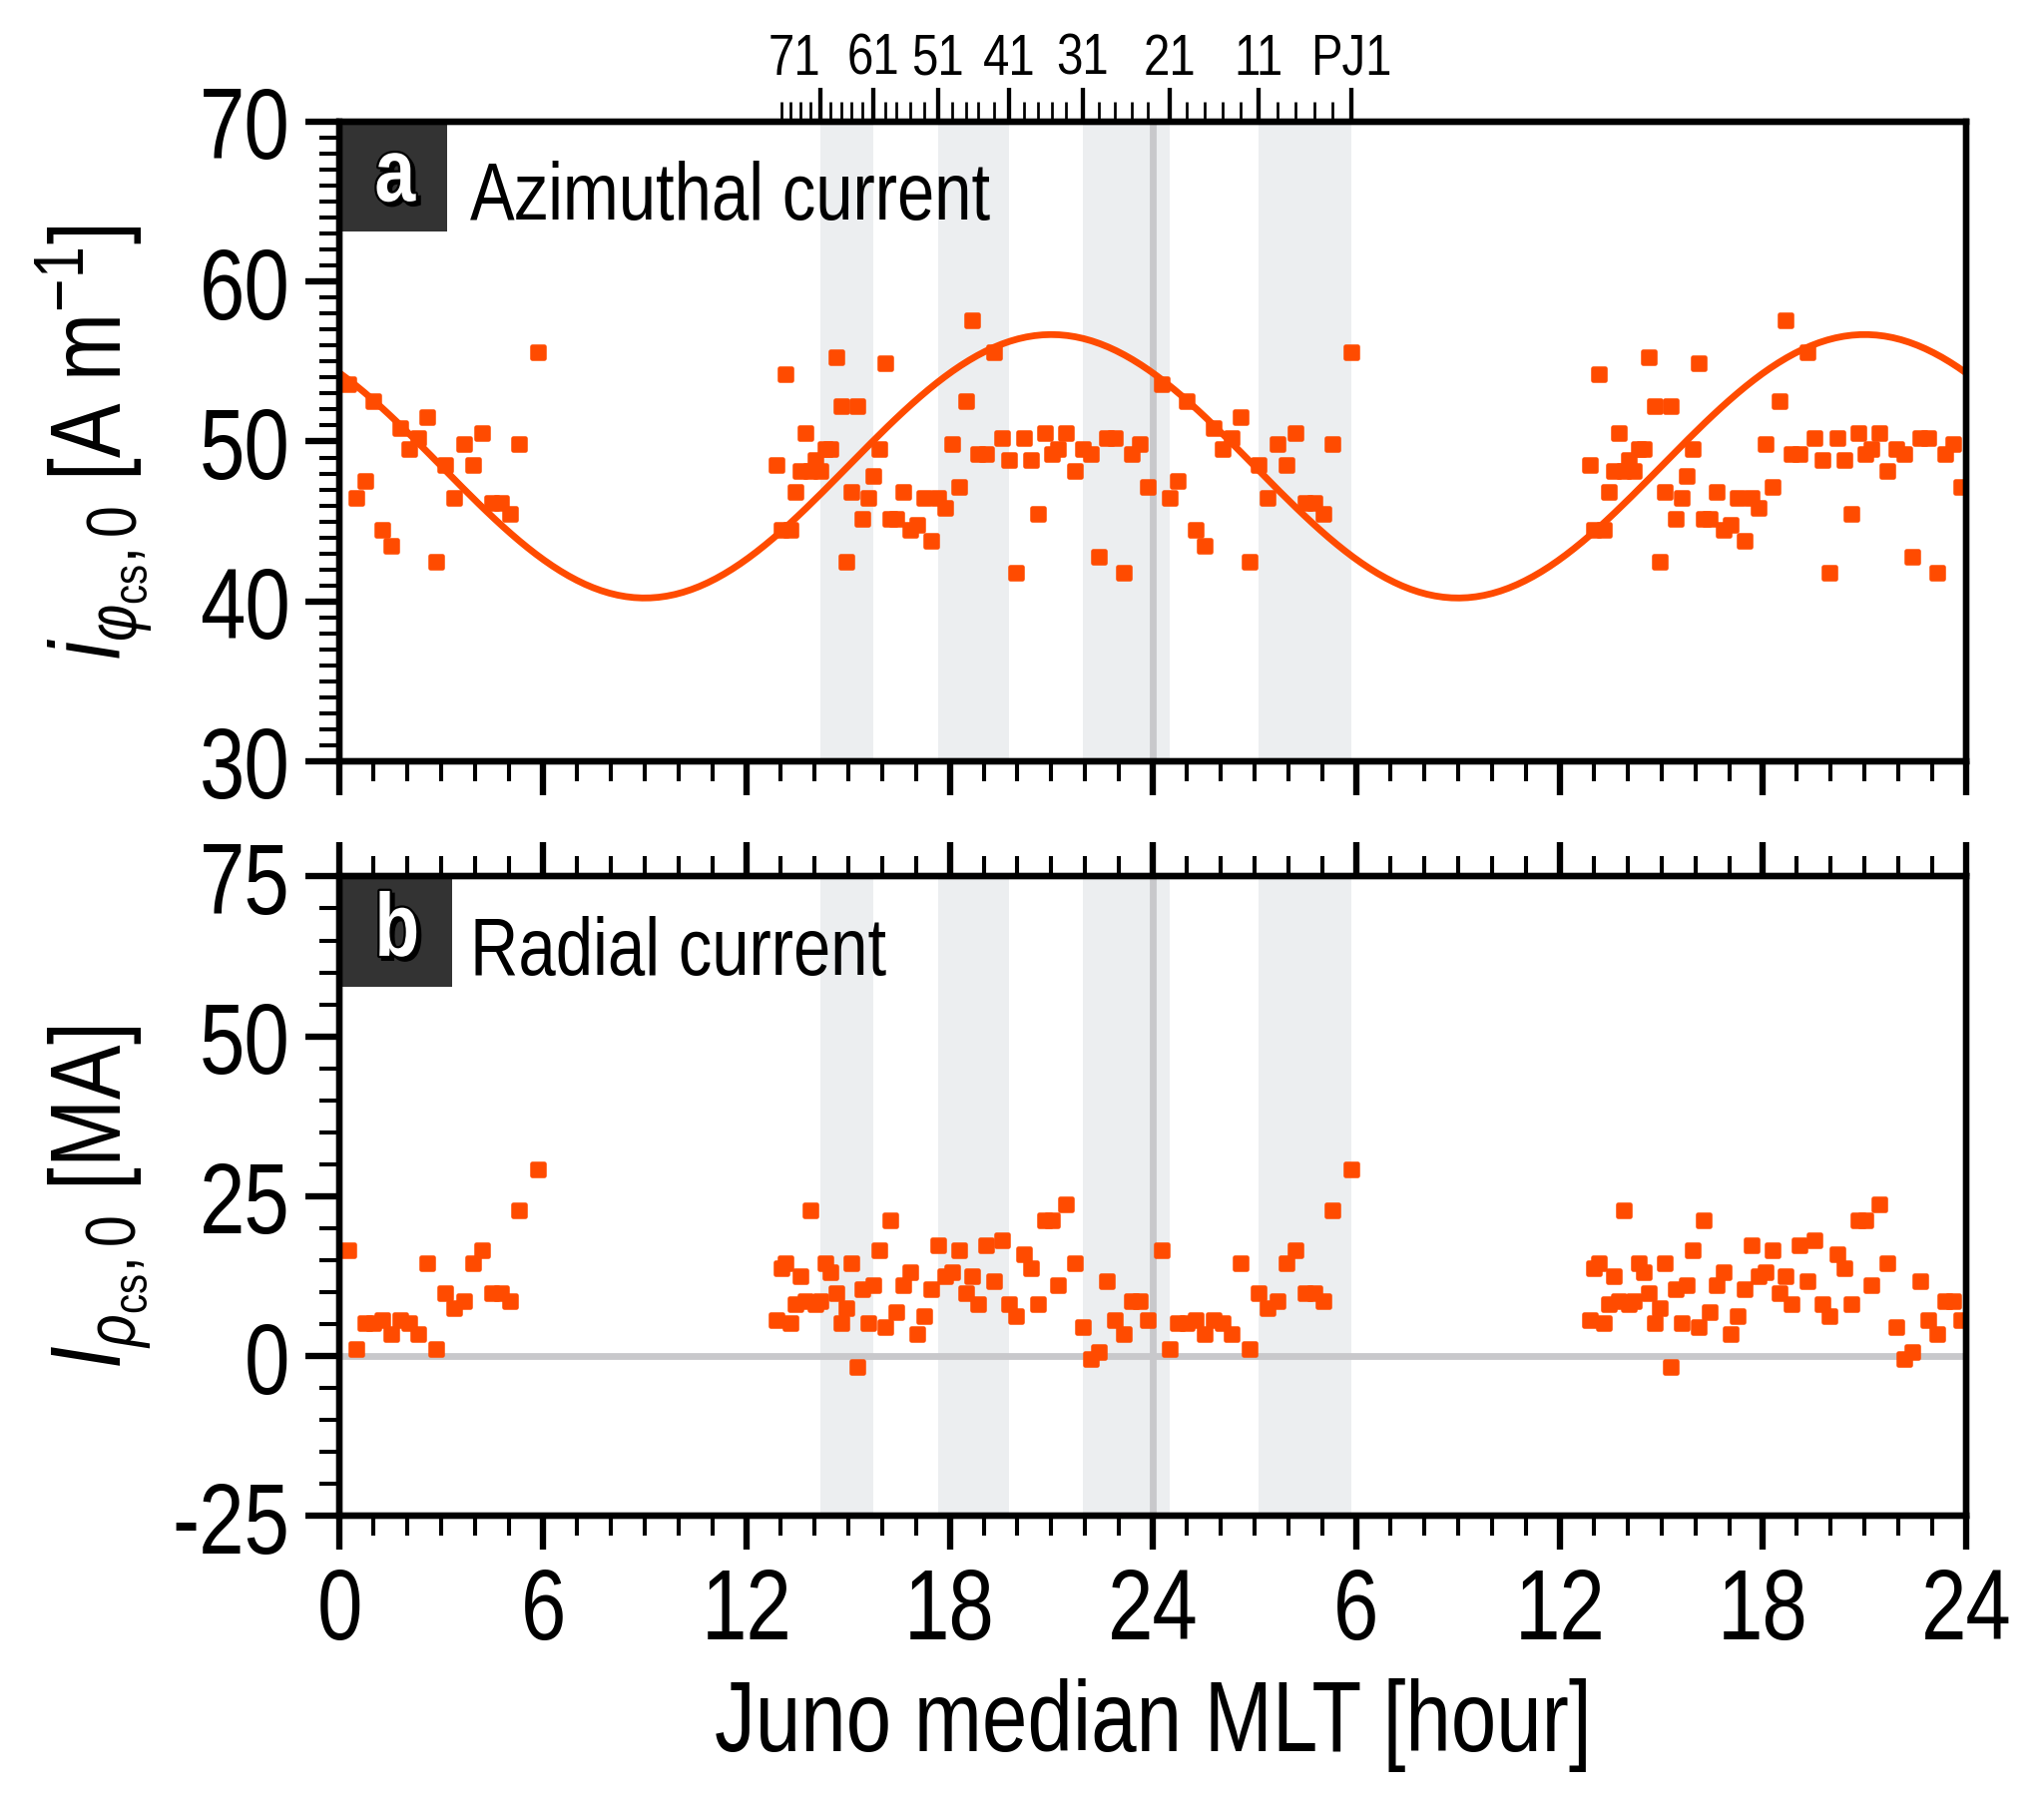

In [10]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=2, figsize=(6.3, 5.5), dpi='XL')
F.hspace = 0.18
F.initialize()

xticks = np.arange(0, 48+1, 6)
xticklabels = np.arange(0, 48+1, 6, dtype=int)
xticklabels[5:] += -24

F.set_xaxis(label=r'Juno median MLT [hour]',
            min=0.0, max=48.0,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=6)
F.set_yaxis(ax_idx=0,
            label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=75,
            ticks=np.arange(-25, 75+1, 25),
            ticklabels=np.arange(-25, 75+1, 25),
            minor_num=5,)

for i in range(2):
    F.ax[0].scatter(f0[:, 6]+24.0*i, f0[:, 1]*1E+6,
                    s=6.0, marker='s', color=UC.red)
    F.ax[1].scatter(f0[:, 6]+24.0*i, f0[:, 3],
                    s=6.0, marker='s', color=UC.red)


for i in range(2):
    F.ax[i].axhline(y=0, color=UC.lightgray, zorder=0.9)
    F.ax[i].axvline(x=24.0, color=UC.lightgray, zorder=0.9)


MLT_fp = np.linspace(0.0, 48.0, 200)
F.ax[0].plot(
    MLT_fp,
    np.average(f0[:, 1]*1E+6)*(1.0+0.17*np.cos(np.pi*(MLT_fp-21.0)/12))
)

# MLT vs PJ
PJ_mlt = np.zeros(80)
for i in range(80):
    if i == 1:
        PJ_mlt[i] = 0.5*(f0[0, 6]+f0[1, 6])+24.0
        continue
    elif i > 21:
        PJ_mlt[i] = f0[i-1, 6]
    elif i == 0:
        PJ_mlt[i] = f0[i, 6]+24.0
    else:
        PJ_mlt[i] = f0[i-1, 6]+24.0
PJax = F.ax[0].twiny()
PJax.set_xlim(0.0, 48.0)
PJax.set_xticks(PJ_mlt[::10])
PJax.set_xticklabels(JUNO_PJ_LABELS[:-1][::10], fontsize=F.fontsize*0.58)
PJax.xaxis.set_minor_locator(FixedLocator(PJ_mlt[::2]))
PJax.tick_params(which='major', width=0.95)
PJax.tick_params(which='minor', width=0.60)
for i, label in enumerate(PJax.get_xticklabels()):
    label.set_transform(
        label.get_transform() +
        plt.matplotlib.transforms.ScaledTranslation(
            0, -3 / 72,
            F.fig.dpi_scale_trans
        )
    )
ticklabels = PJax.get_xticklabels()
ticklabels[-1].set_ha('right')
PJax.set_xticklabels(ticklabels)

# Shades in each 10 perijove
for i in range(2):
    for j in range(4):
        F.ax[i].axvspan(PJ_mlt[20*j], PJ_mlt[10+20*j],
                        fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)

F.ax[0].text(0.08, 0.94,
             'Azimuthal current',
             color='k',
             fontsize=F.fontsize*0.82,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[1].text(0.08, 0.94,
             'Radial current',
             color='k',
             fontsize=F.fontsize*0.82,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[1].transAxes)

[4.84531585e+01 2.39288182e-02 2.54465860e+00]


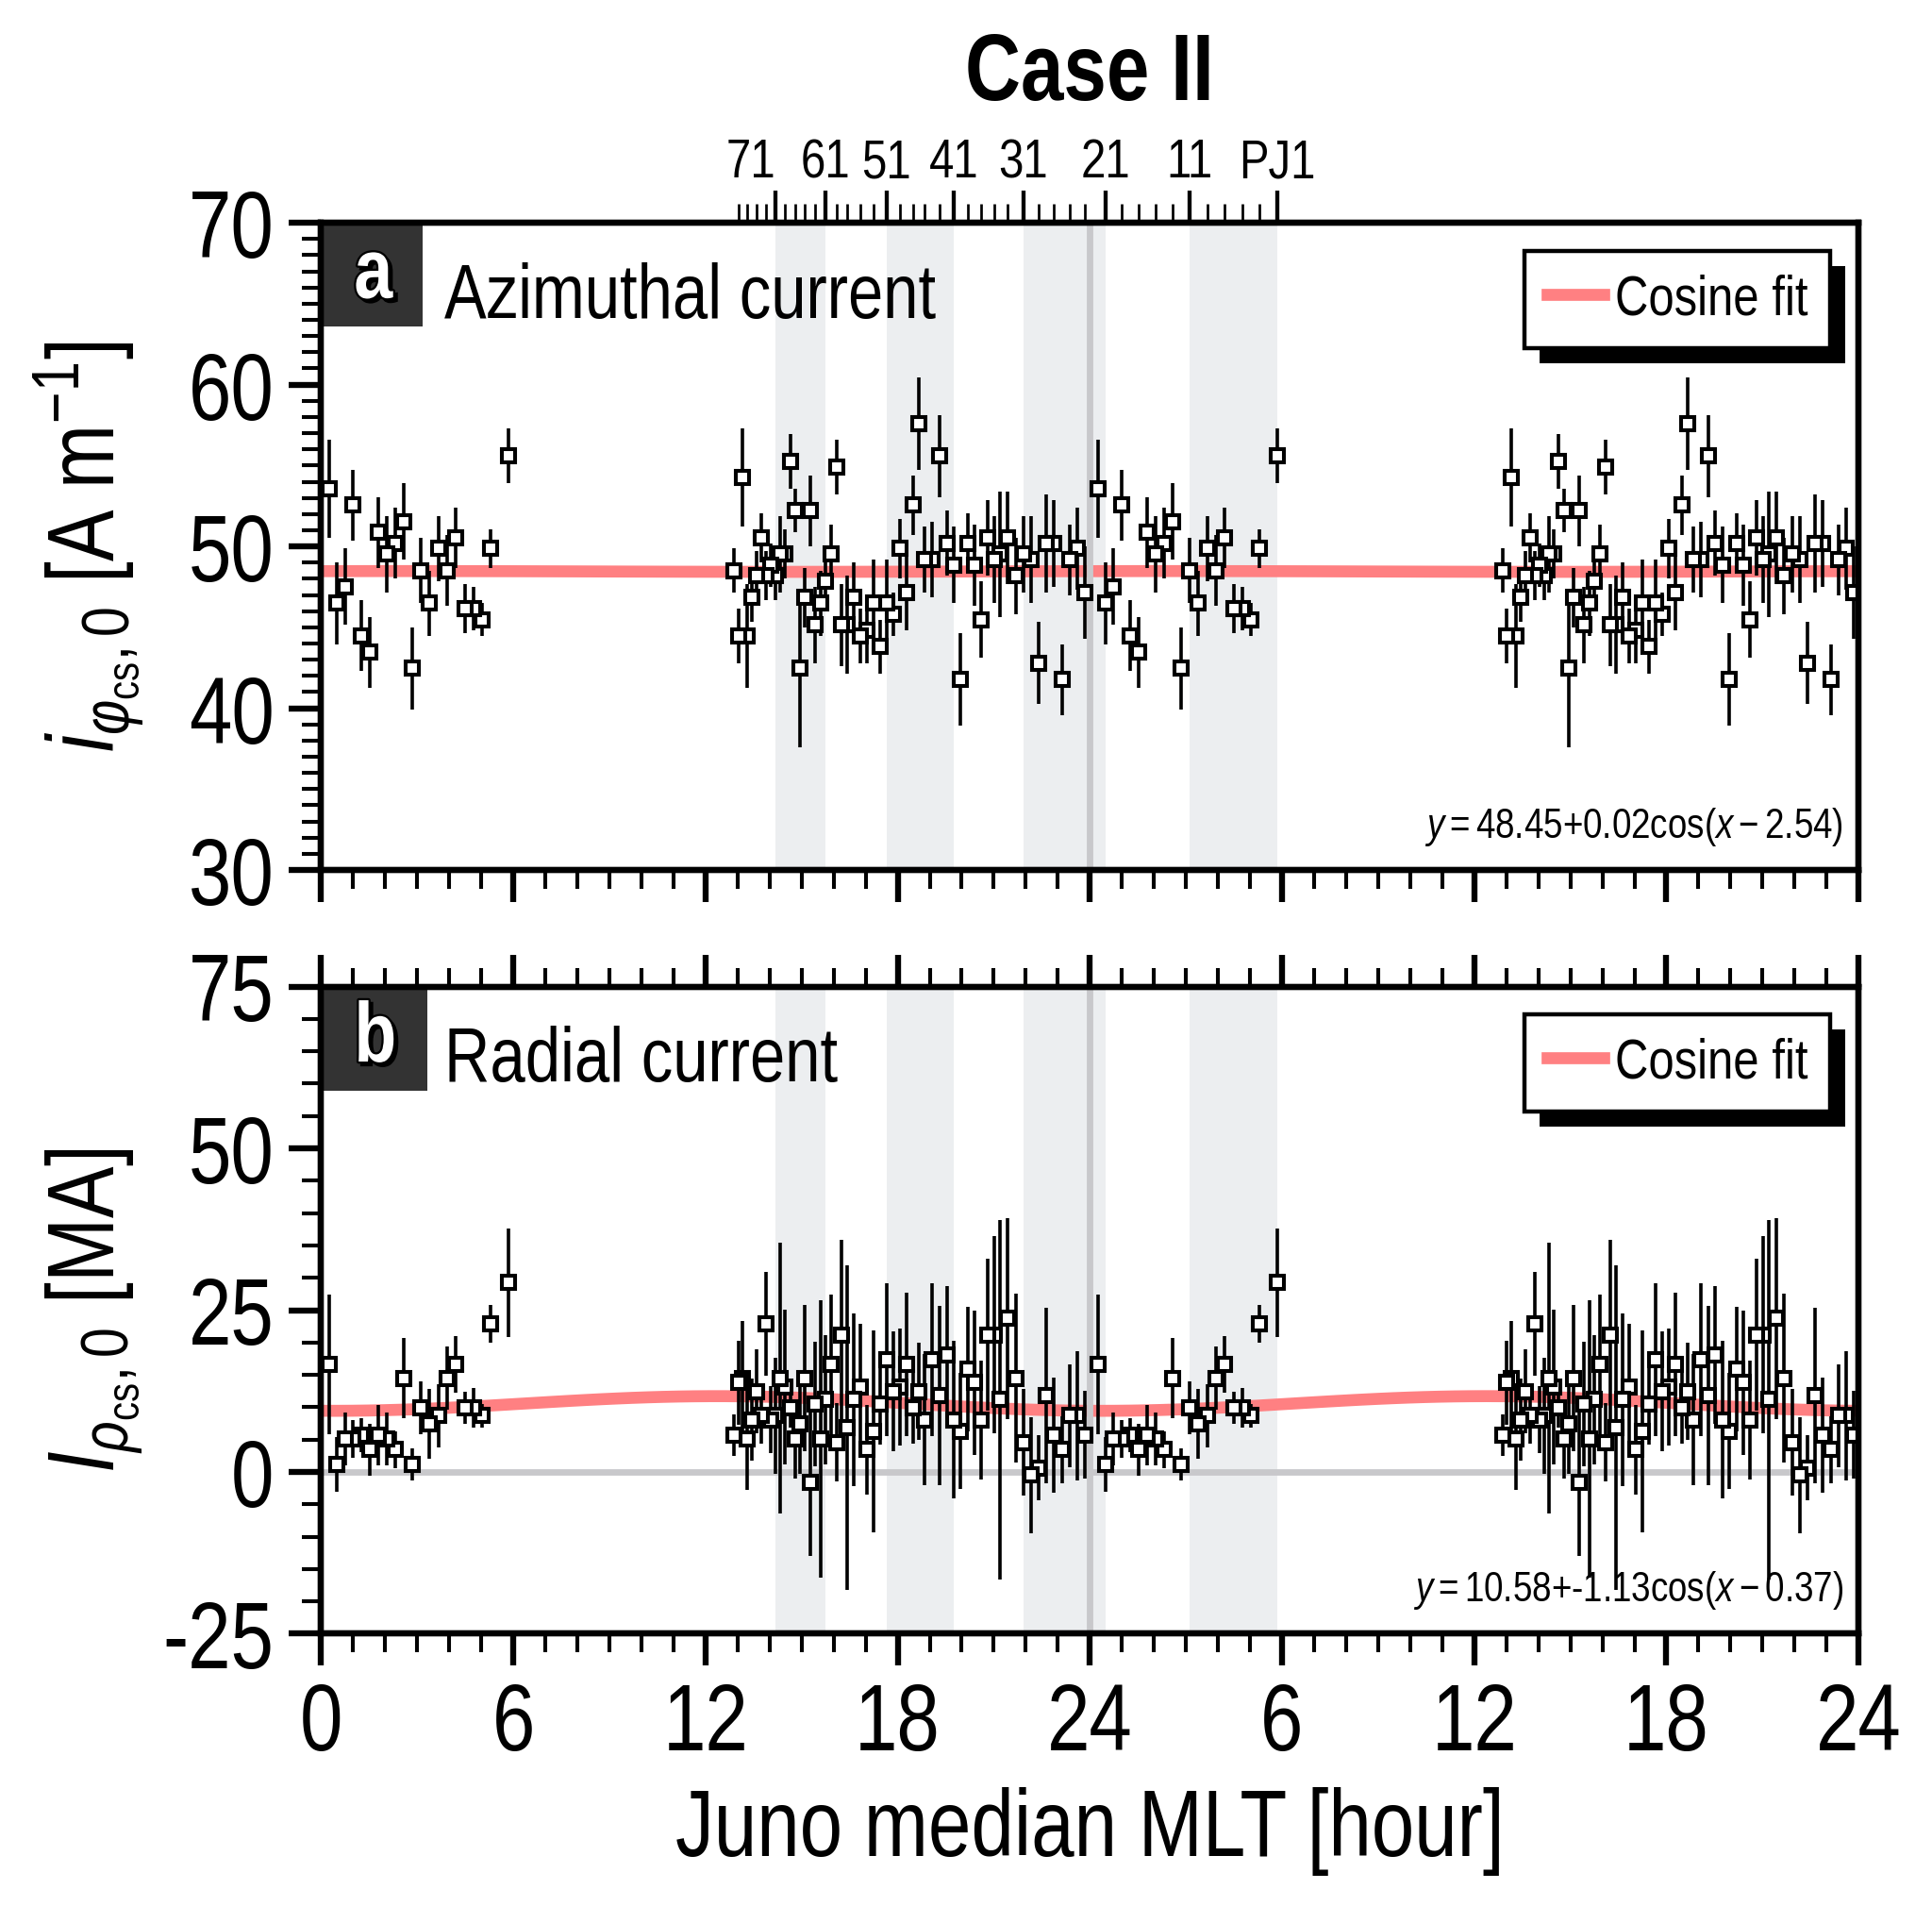

In [11]:
def func(X, a0, a1, a2):  # 2次式近似
    """
    Args:
        X (_type_): MLT [hr]
        a0 (_type_): _description_
        a1 (_type_): _description_
        a2 (_type_): _description_
    """
    MLT_rad = 2*np.pi*(X-a2)/24.0
    Y = a0 + a1*np.cos(MLT_rad)
    return Y


F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=2, figsize=(6.3, 5.8), dpi='XL')
F.hspace = 0.18
F.initialize()

xticks = np.arange(0, 48+1, 6)
xticklabels = np.arange(0, 48+1, 6, dtype=int)
xticklabels[5:] += -24

F.set_xaxis(label=r'Juno median MLT [hour]',
            min=0.0, max=48.0,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=6)
F.set_yaxis(ax_idx=0,
            label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=75,
            ticks=np.arange(-25, 75+1, 25),
            ticklabels=np.arange(-25, 75+1, 25),
            minor_num=5,)

for i in range(2):
    # F.ax[0].scatter(f0[:, 6]+24.0*i, f0[:, 1]*1E+6,
    #                 s=6.0, marker='s', color=UC.red)
    F.ax[0].errorbar(x=f0[:, 6]+24.0*i, y=f0[:, 1]*1E+6,
                     yerr=f0[:, 2]*1E+6, color='k',
                     elinewidth=0.8, linewidth=0.,
                     marker='s', markersize=2.9,
                     markeredgecolor='k', markerfacecolor='w',
                     markeredgewidth=0.9,
                     zorder=4)
for i in range(2):
    F.ax[1].errorbar(x=f0[:, 6]+24.0*i, y=f0[:, 3],
                     yerr=f0[:, 4], color='k',
                     elinewidth=0.8, linewidth=0.,
                     marker='s', markersize=2.9,
                     markeredgecolor='k', markerfacecolor='w',
                     markeredgewidth=0.9,
                     zorder=4)

"""# Footprint latitudeで求めたMLT依存性
MLT0 = 21.4                             # [hr]
mlt_fit = np.linspace(0.0, 48.0, 50)    # [hr]
i_phi0_ave = np.average(f0[:, 1]*1E+6)
i_phi0_cos = i_phi0_ave*(1.0-0.10*np.cos(2.0*np.pi*(mlt_fit-MLT0)/24.0))
F.ax[0].plot(mlt_fit, i_phi0_cos, color=UC.lightlightblue,
             linewidth=2.0, zorder=0.9)"""

# i_phi0を三角関数でフィッティング
i_phi0 = f0[np.argsort(f0[:, 6]), 1]*1E+6
Juno_MLT_arr = np.sort(f0[:, 6])
popt_i_phi0, _ = curve_fit(func, Juno_MLT_arr, i_phi0)  # poptは最適推定値、pcovは共分散
MLT_arr = np.linspace(0.0, 48.0, 100)
I_phi0_fit = func(MLT_arr, popt_i_phi0[0], popt_i_phi0[1], popt_i_phi0[2])
F.ax[0].plot(MLT_arr, I_phi0_fit, color=linecolor,
             linewidth=2.8, label='Cosine fit',
             zorder=0.9)
y_fit_label = r'$y=$' + \
    str(round(popt_i_phi0[0], 2)) + '+' + str(round(popt_i_phi0[1], 2)) + \
    r'cos$(x-$' + str(round(popt_i_phi0[2], 2)) + '$)$'
F.ax[0].text(0.99, 0.1,
             y_fit_label,
             color='k',
             fontsize=F.fontsize*0.45,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)
legend = F.legend(ax_idx=0, loc='upper right',
                  ncol=3, markerscale=3.5,
                  fontsize_scale=0.6, textcolor=False, handletextpad=0.2)
legend_shadow(fig=F.fig, ax=F.ax[0], legend=legend, d=1.0)
print(popt_i_phi0)

# I_rho0を三角関数でフィッティング
I_rho0 = f0[np.argsort(f0[:, 6]), 3]
Juno_MLT_arr = np.sort(f0[:, 6])
popt_I_rho0, _ = curve_fit(func, Juno_MLT_arr, I_rho0)  # poptは最適推定値、pcovは共分散
MLT_arr = np.linspace(0.0, 48.0, 100)
I_rho0_fit = func(MLT_arr, popt_I_rho0[0], popt_I_rho0[1], popt_I_rho0[2])
F.ax[1].plot(MLT_arr, I_rho0_fit, color=linecolor,
             linewidth=2.8, label='Cosine fit',
             zorder=0.9)
y_fit_label = r'$y=$' + \
    str(round(popt_I_rho0[0], 2)) + '+' + str(round(popt_I_rho0[1], 2)) + \
    r'cos$(x-$' + str(round(np.mod(popt_I_rho0[2], 24.0), 2)) + '$)$'
F.ax[1].text(0.99, 0.1,
             y_fit_label,
             color='k',
             fontsize=F.fontsize*0.45,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[1].transAxes)


# MLT vs PJ
PJ_mlt = np.zeros(80)
for i in range(80):
    if i == 1:
        PJ_mlt[i] = 0.5*(f0[0, 6]+f0[1, 6])+24.0
        continue
    elif i > 21:
        PJ_mlt[i] = f0[i-1, 6]
    elif i == 0:
        PJ_mlt[i] = f0[i, 6]+24.0
    else:
        PJ_mlt[i] = f0[i-1, 6]+24.0
PJax = F.ax[0].twiny()
PJax.set_xlim(0.0, 48.0)
PJax.set_xticks(PJ_mlt[::10])
PJax.set_xticklabels(JUNO_PJ_LABELS[:-1][::10], fontsize=F.fontsize*0.58)
PJax.xaxis.set_minor_locator(FixedLocator(PJ_mlt[::2]))
PJax.tick_params(which='major', width=0.95)
PJax.tick_params(which='minor', width=0.60)
for i, label in enumerate(PJax.get_xticklabels()):
    label.set_transform(
        label.get_transform() +
        plt.matplotlib.transforms.ScaledTranslation(
            0, -3 / 72,
            F.fig.dpi_scale_trans
        )
    )
ticklabels = PJax.get_xticklabels()
ticklabels[-1].set_ha('right')
PJax.set_xticklabels(ticklabels)

# Shades in each 10 perijove
for i in range(2):
    for j in range(4):
        F.ax[i].axvspan(PJ_mlt[20*j], PJ_mlt[10+20*j],
                        fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)

F.ax[0].text(0.08, 0.94,
             'Azimuthal current',
             color='k',
             fontsize=F.fontsize*0.82,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[1].text(0.08, 0.94,
             'Radial current',
             color='k',
             fontsize=F.fontsize*0.82,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[1].transAxes)

legend = F.legend(ax_idx=1, loc='upper right',
                  ncol=3, markerscale=3.5,
                  fontsize_scale=0.6, textcolor=False, handletextpad=0.2)
legend_shadow(fig=F.fig, ax=F.ax[1], legend=legend, d=1.0)

for i in range(2):
    F.ax[i].axhline(y=0, color=UC.lightgray, zorder=0.9)
    F.ax[i].axvline(x=24.0, color=UC.lightgray, zorder=0.9)

F.ax[0].set_title(case, weight='bold')

plt.savefig('img/'+dir[8:]+'_MLT_fit_002.pdf',
            bbox_inches='tight')

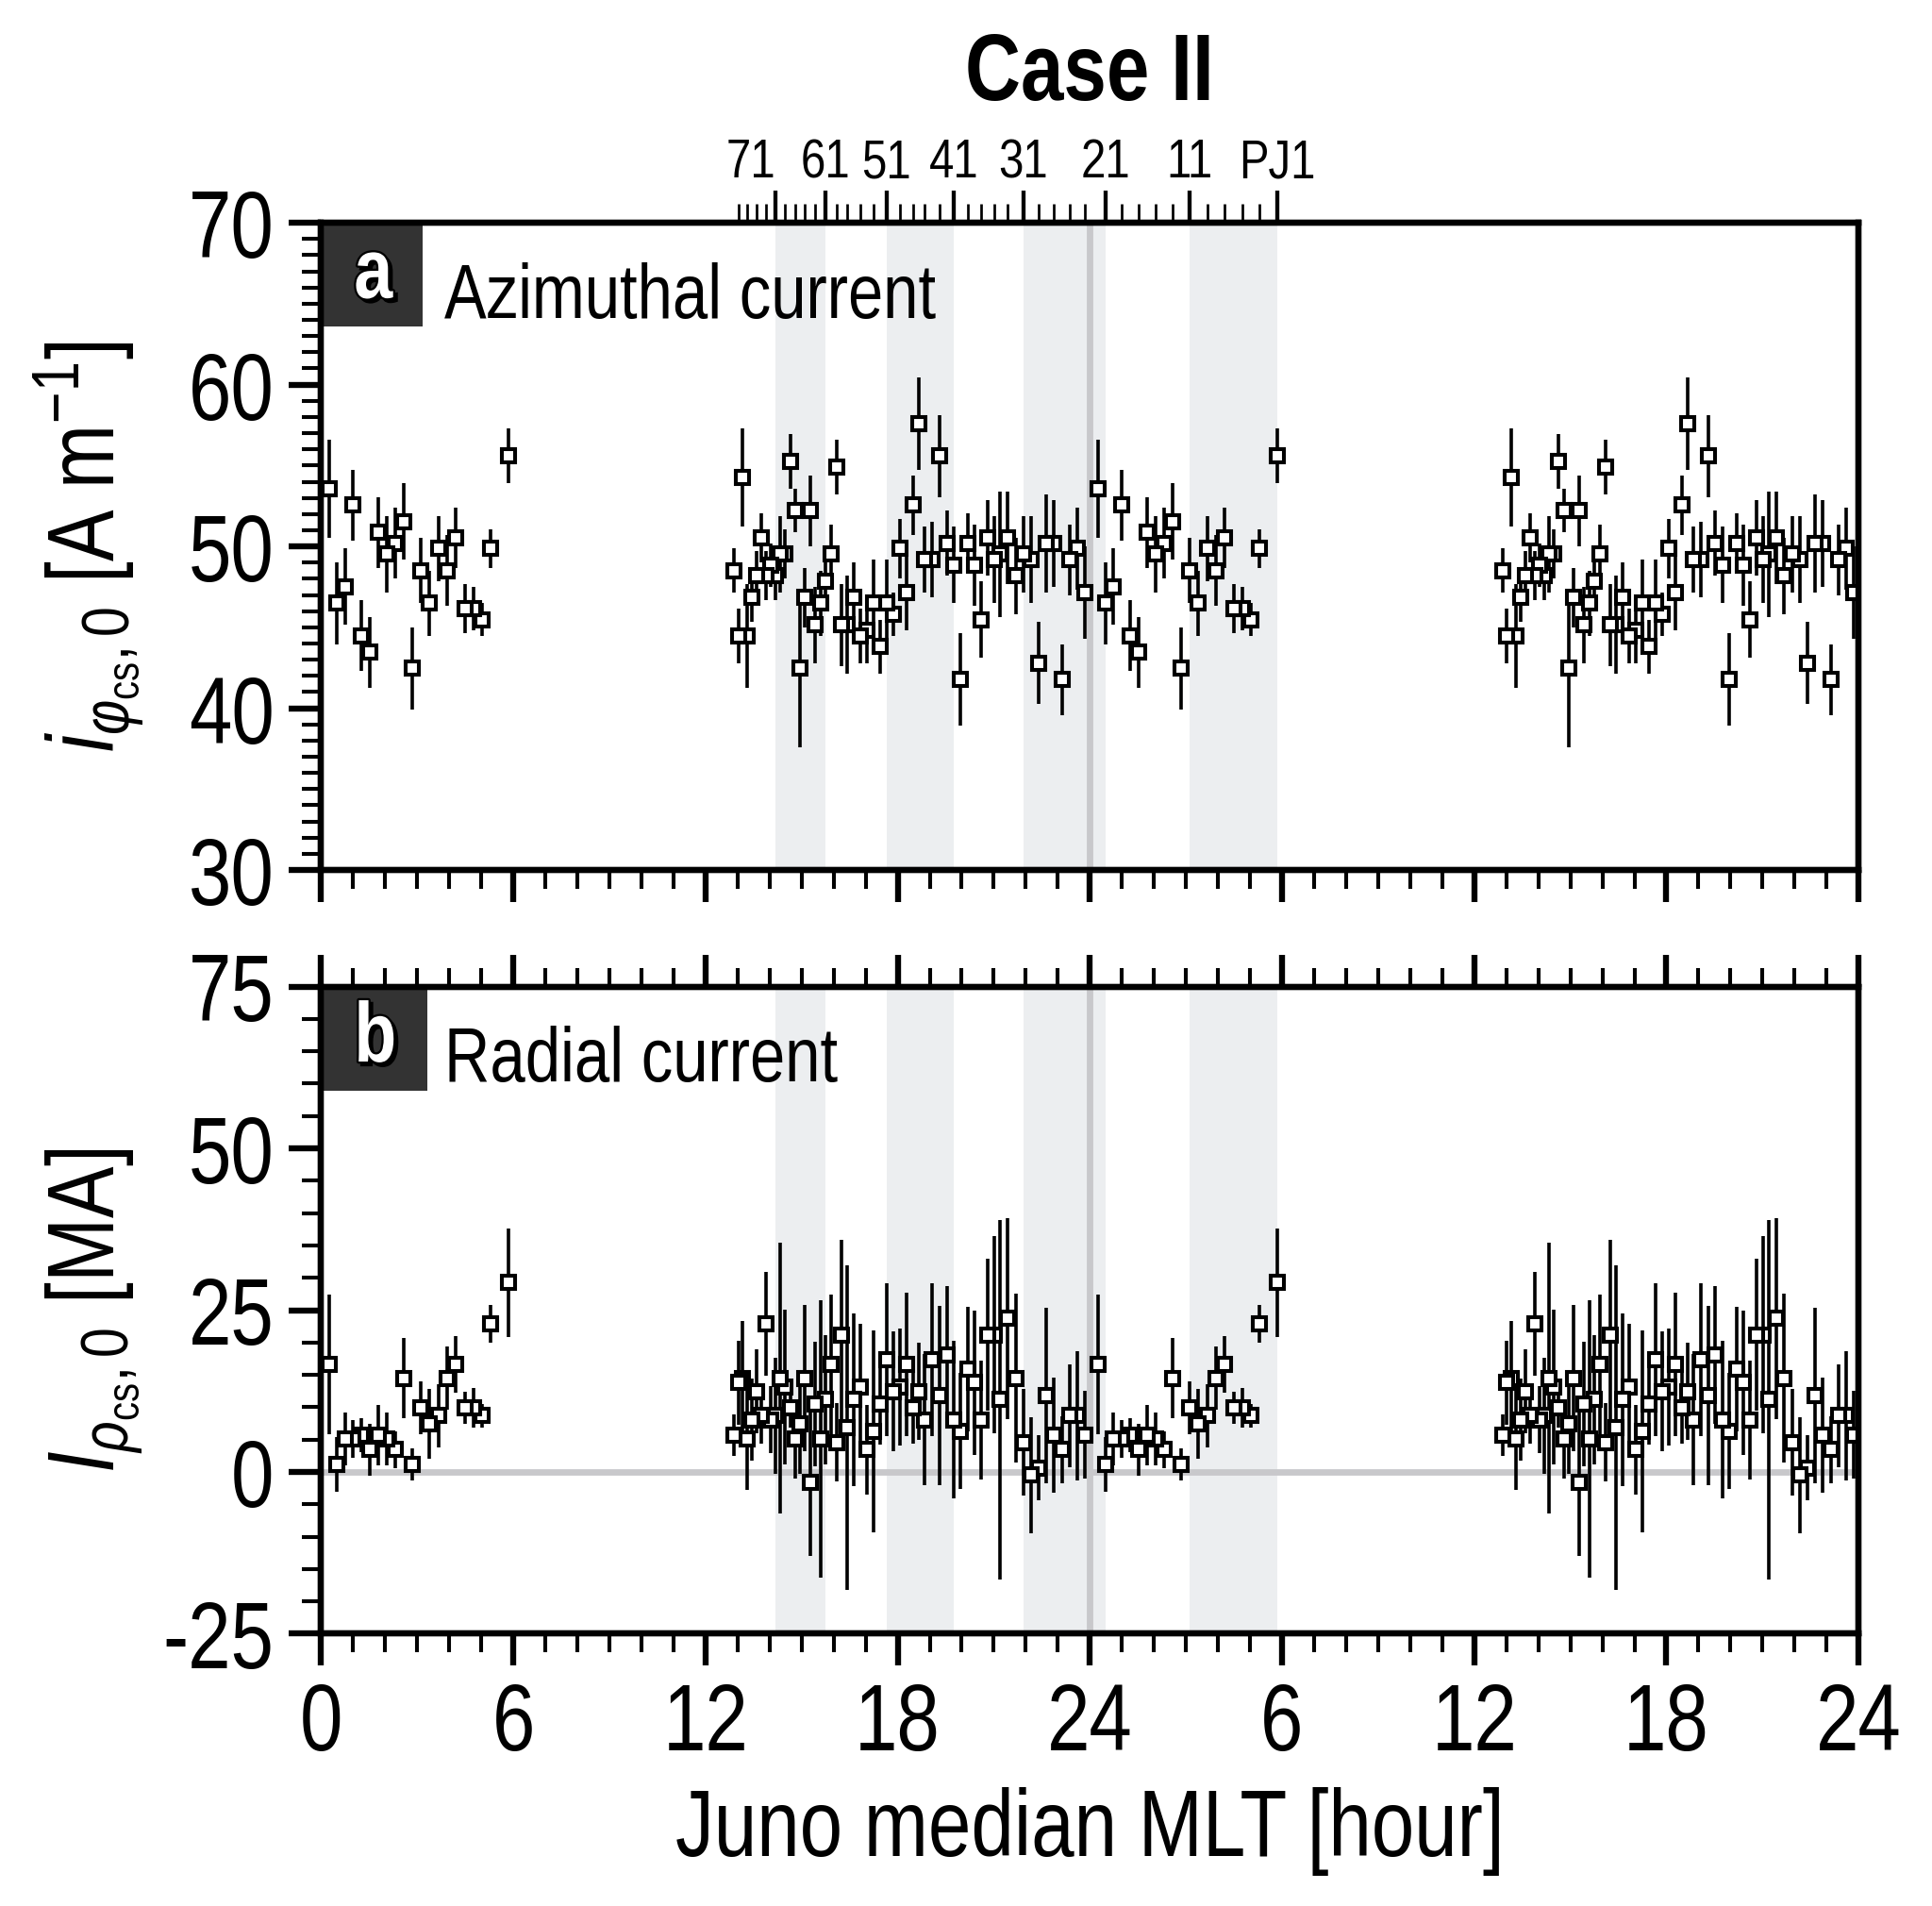

In [12]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=2, figsize=(6.3, 5.8), dpi='XL')
F.hspace = 0.18
F.initialize()

xticks = np.arange(0, 48+1, 6)
xticklabels = np.arange(0, 48+1, 6, dtype=int)
xticklabels[5:] += -24

F.set_xaxis(label=r'Juno median MLT [hour]',
            min=0.0, max=48.0,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=6)
F.set_yaxis(ax_idx=0,
            label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=75,
            ticks=np.arange(-25, 75+1, 25),
            ticklabels=np.arange(-25, 75+1, 25),
            minor_num=5,)

for i in range(2):
    # F.ax[0].scatter(f0[:, 6]+24.0*i, f0[:, 1]*1E+6,
    #                 s=6.0, marker='s', color=UC.red)
    F.ax[0].errorbar(x=f0[:, 6]+24.0*i, y=f0[:, 1]*1E+6,
                     yerr=f0[:, 2]*1E+6, color='k',
                     elinewidth=0.8, linewidth=0.,
                     marker='s', markersize=2.9,
                     markeredgecolor='k', markerfacecolor='w',
                     markeredgewidth=0.9,
                     zorder=4)
for i in range(2):
    F.ax[1].errorbar(x=f0[:, 6]+24.0*i, y=f0[:, 3],
                     yerr=f0[:, 4], color='k',
                     elinewidth=0.8, linewidth=0.,
                     marker='s', markersize=2.9,
                     markeredgecolor='k', markerfacecolor='w',
                     markeredgewidth=0.9,
                     zorder=4)

for i in range(2):
    F.ax[i].axhline(y=0, color=UC.lightgray, zorder=0.9)
    F.ax[i].axvline(x=24.0, color=UC.lightgray, zorder=0.9)


# MLT vs PJ
PJ_mlt = np.zeros(80)
for i in range(80):
    if i == 1:
        PJ_mlt[i] = 0.5*(f0[0, 6]+f0[1, 6])+24.0
        continue
    elif i > 21:
        PJ_mlt[i] = f0[i-1, 6]
    elif i == 0:
        PJ_mlt[i] = f0[i, 6]+24.0
    else:
        PJ_mlt[i] = f0[i-1, 6]+24.0
PJax = F.ax[0].twiny()
PJax.set_xlim(0.0, 48.0)
PJax.set_xticks(PJ_mlt[::10])
PJax.set_xticklabels(JUNO_PJ_LABELS[:-1][::10], fontsize=F.fontsize*0.58)
PJax.xaxis.set_minor_locator(FixedLocator(PJ_mlt[::2]))
PJax.tick_params(which='major', width=0.95)
PJax.tick_params(which='minor', width=0.60)
for i, label in enumerate(PJax.get_xticklabels()):
    label.set_transform(
        label.get_transform() +
        plt.matplotlib.transforms.ScaledTranslation(
            0, -3 / 72,
            F.fig.dpi_scale_trans
        )
    )
ticklabels = PJax.get_xticklabels()
ticklabels[-1].set_ha('right')
PJax.set_xticklabels(ticklabels)

# Shades in each 10 perijove
for i in range(2):
    for j in range(4):
        F.ax[i].axvspan(PJ_mlt[20*j], PJ_mlt[10+20*j],
                        fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)

F.ax[0].text(0.08, 0.94,
             'Azimuthal current',
             color='k',
             fontsize=F.fontsize*0.82,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[1].text(0.08, 0.94,
             'Radial current',
             color='k',
             fontsize=F.fontsize*0.82,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[1].transAxes)

F.ax[0].set_title(case, weight='bold')

plt.savefig('img/'+dir[8:]+'_MLT_fit_002_a.pdf',
            bbox_inches='tight')

[4.84531585e+01 2.39288182e-02 2.54465860e+00]


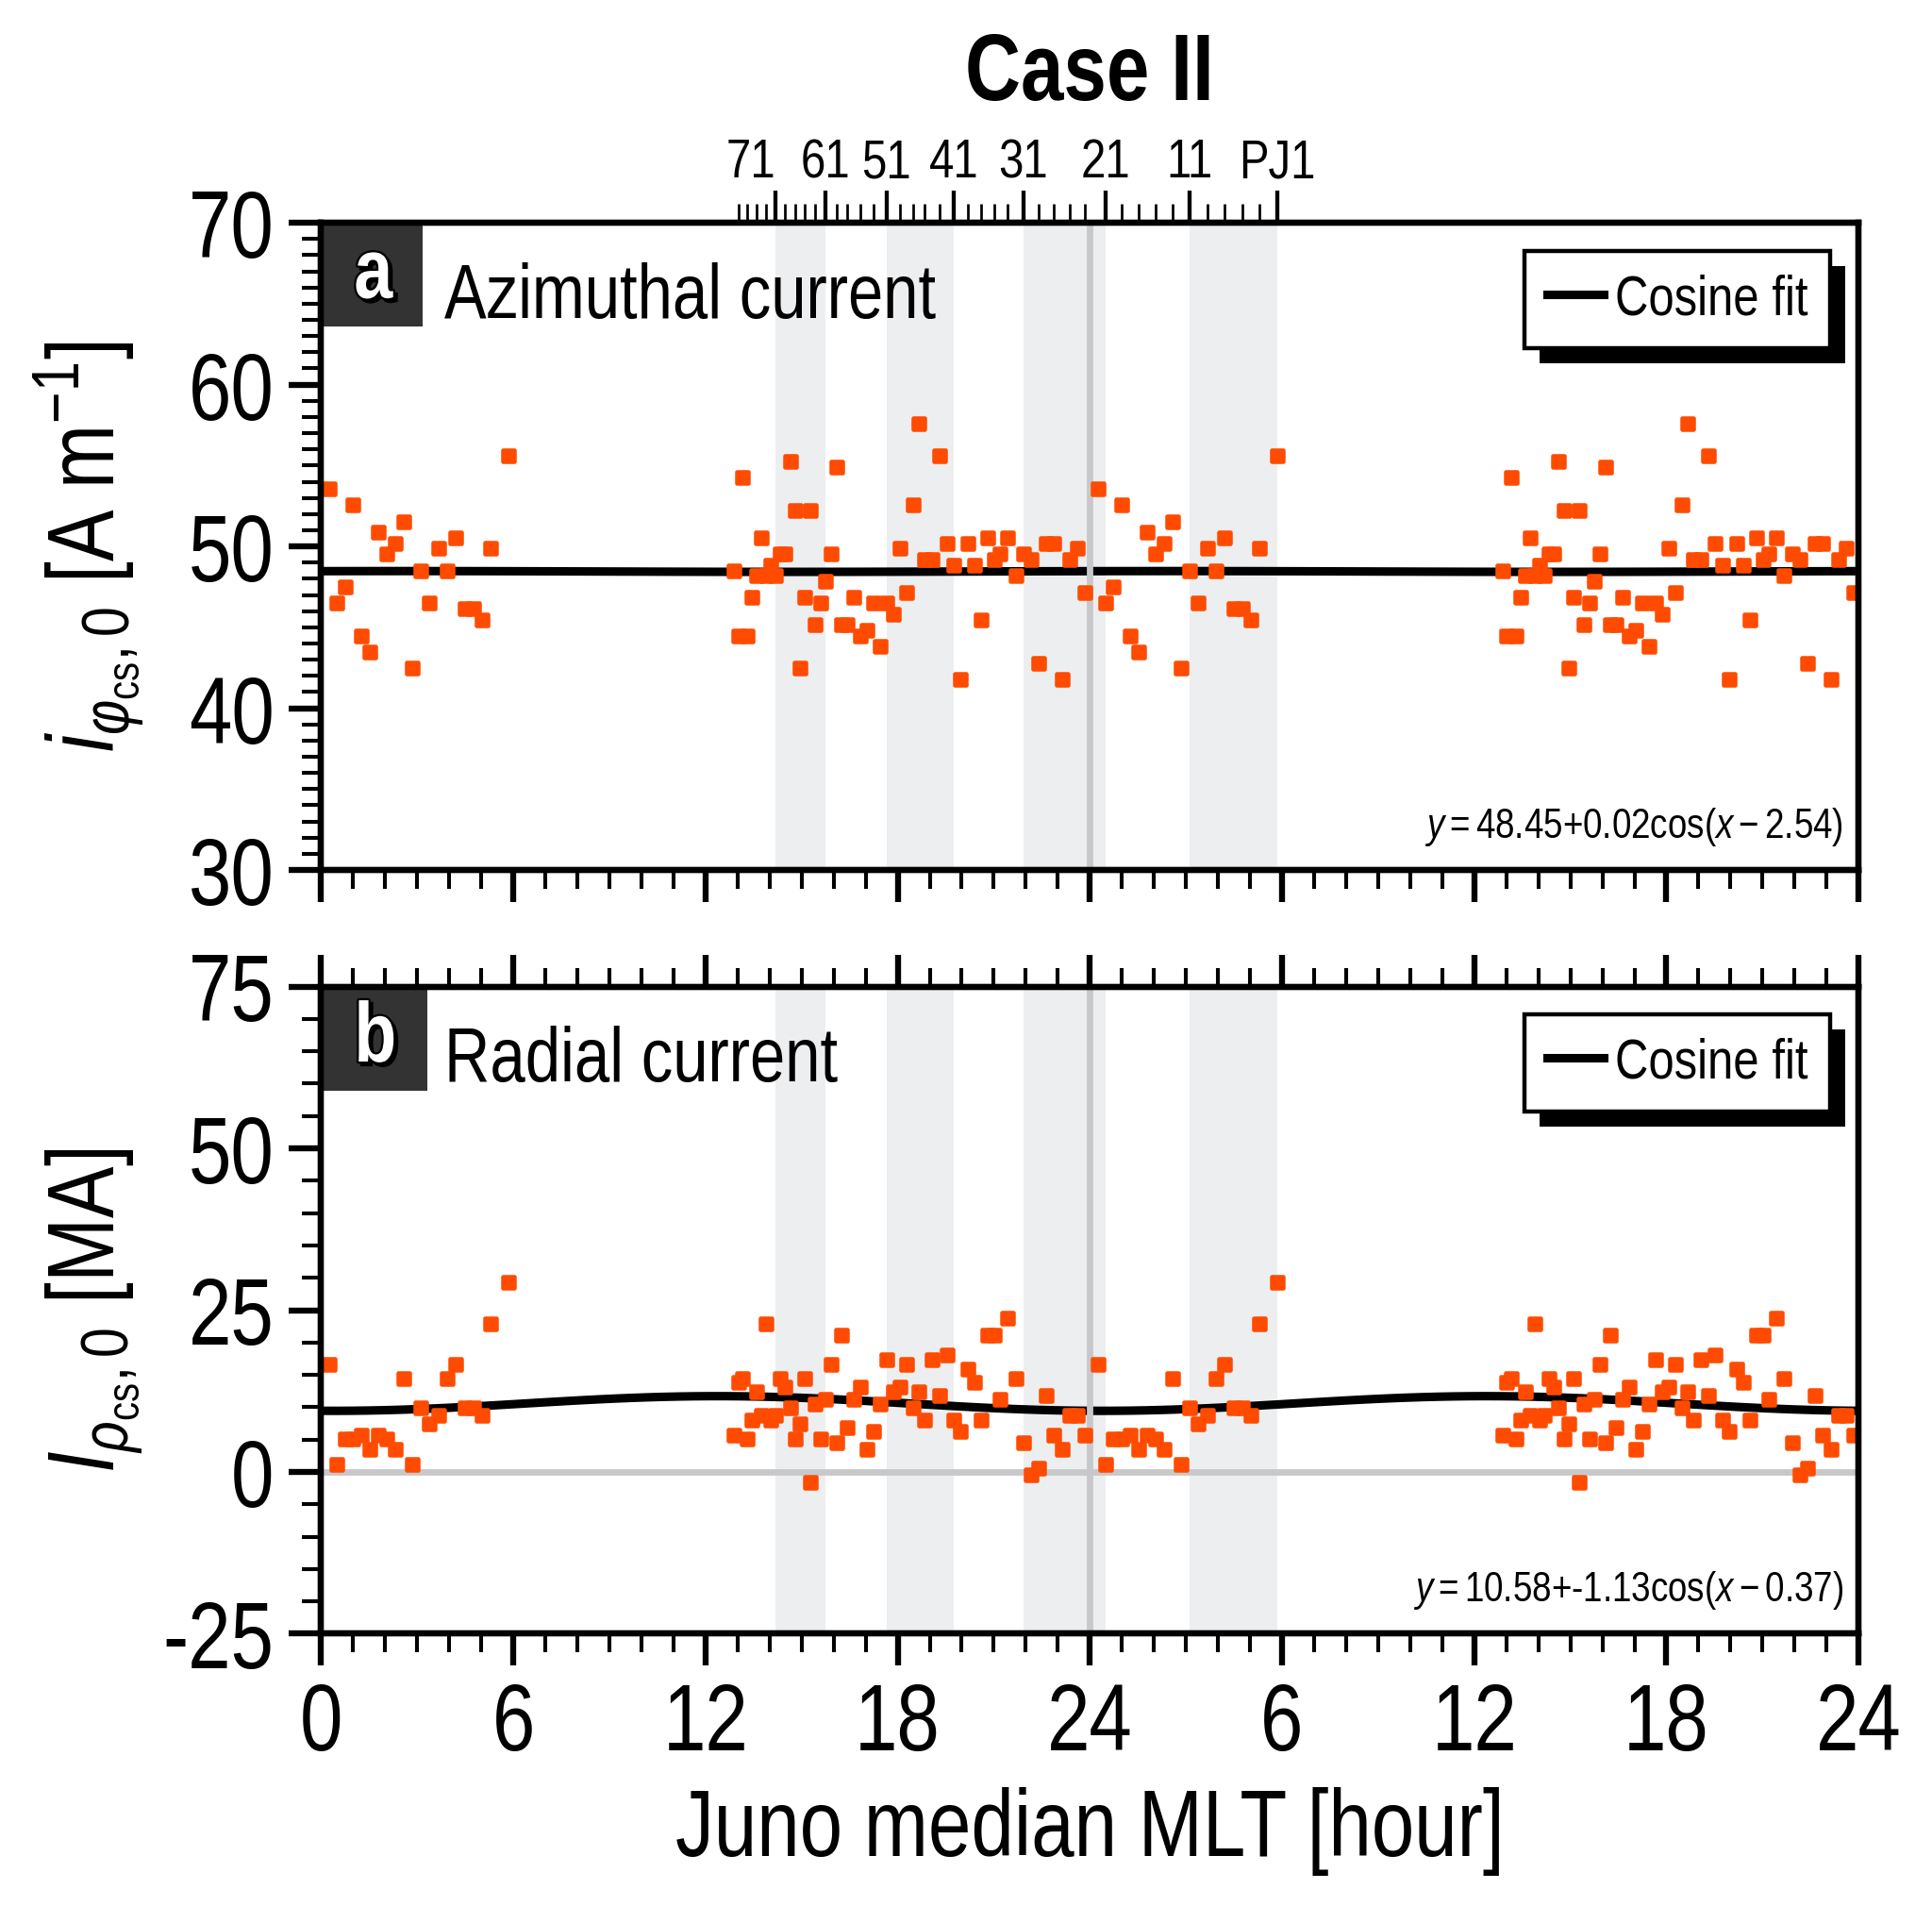

In [13]:
def func(X, a0, a1, a2):  # 2次式近似
    """
    Args:
        X (_type_): MLT [hr]
        a0 (_type_): _description_
        a1 (_type_): _description_
        a2 (_type_): _description_
    """
    MLT_rad = 2*np.pi*(X-a2)/24.0
    Y = a0 + a1*np.cos(MLT_rad)
    return Y


F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=2, figsize=(6.3, 5.8), dpi='XL')
F.hspace = 0.18
F.initialize()

xticks = np.arange(0, 48+1, 6)
xticklabels = np.arange(0, 48+1, 6, dtype=int)
xticklabels[5:] += -24

F.set_xaxis(label=r'Juno median MLT [hour]',
            min=0.0, max=48.0,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=6)
F.set_yaxis(ax_idx=0,
            label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=75,
            ticks=np.arange(-25, 75+1, 25),
            ticklabels=np.arange(-25, 75+1, 25),
            minor_num=5,)

for i in range(2):
    F.ax[0].scatter(f0[:, 6]+24.0*i, f0[:, 1]*1E+6,
                    s=6.0, marker='s', color=UC.red)
    F.ax[1].scatter(f0[:, 6]+24.0*i, f0[:, 3],
                    s=6.0, marker='s', color=UC.red)

"""# Footprint latitudeで求めたMLT依存性
MLT0 = 21.4                             # [hr]
mlt_fit = np.linspace(0.0, 48.0, 50)    # [hr]
i_phi0_ave = np.average(f0[:, 1]*1E+6)
i_phi0_cos = i_phi0_ave*(1.0-0.10*np.cos(2.0*np.pi*(mlt_fit-MLT0)/24.0))
F.ax[0].plot(mlt_fit, i_phi0_cos, color=UC.lightlightblue,
             linewidth=2.0, zorder=0.9)"""

# i_phi0を三角関数でフィッティング
i_phi0 = f0[np.argsort(f0[:, 6]), 1]*1E+6
Juno_MLT_arr = np.sort(f0[:, 6])
popt_i_phi0, _ = curve_fit(func, Juno_MLT_arr, i_phi0)  # poptは最適推定値、pcovは共分散
MLT_arr = np.linspace(0.0, 48.0, 100)
I_phi0_fit = func(MLT_arr, popt_i_phi0[0], popt_i_phi0[1], popt_i_phi0[2])
F.ax[0].plot(MLT_arr, I_phi0_fit, color='k',
             linewidth=2.0, label='Cosine fit',
             zorder=0.9)
y_fit_label = r'$y=$' + \
    str(round(popt_i_phi0[0], 2)) + '+' + str(round(popt_i_phi0[1], 2)) + \
    r'cos$(x-$' + str(round(popt_i_phi0[2], 2)) + '$)$'
F.ax[0].text(0.99, 0.1,
             y_fit_label,
             color='k',
             fontsize=F.fontsize*0.45,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)
legend = F.legend(ax_idx=0, loc='upper right',
                  ncol=3, markerscale=3.5,
                  fontsize_scale=0.6, textcolor=False, handletextpad=0.2)
legend_shadow(fig=F.fig, ax=F.ax[0], legend=legend, d=1.0)
print(popt_i_phi0)

# I_rho0を三角関数でフィッティング
I_rho0 = f0[np.argsort(f0[:, 6]), 3]
Juno_MLT_arr = np.sort(f0[:, 6])
popt_I_rho0, _ = curve_fit(func, Juno_MLT_arr, I_rho0)  # poptは最適推定値、pcovは共分散
MLT_arr = np.linspace(0.0, 48.0, 100)
I_rho0_fit = func(MLT_arr, popt_I_rho0[0], popt_I_rho0[1], popt_I_rho0[2])
F.ax[1].plot(MLT_arr, I_rho0_fit, color='k',
             linewidth=2.0, label='Cosine fit',
             zorder=0.9)
y_fit_label = r'$y=$' + \
    str(round(popt_I_rho0[0], 2)) + '+' + str(round(popt_I_rho0[1], 2)) + \
    r'cos$(x-$' + str(round(np.mod(popt_I_rho0[2], 24.0), 2)) + '$)$'
F.ax[1].text(0.99, 0.1,
             y_fit_label,
             color='k',
             fontsize=F.fontsize*0.45,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[1].transAxes)

# MLT vs PJ
PJ_mlt = np.zeros(80)
for i in range(80):
    if i == 1:
        PJ_mlt[i] = 0.5*(f0[0, 6]+f0[1, 6])+24.0
        continue
    elif i > 21:
        PJ_mlt[i] = f0[i-1, 6]
    elif i == 0:
        PJ_mlt[i] = f0[i, 6]+24.0
    else:
        PJ_mlt[i] = f0[i-1, 6]+24.0
PJax = F.ax[0].twiny()
PJax.set_xlim(0.0, 48.0)
PJax.set_xticks(PJ_mlt[::10])
PJax.set_xticklabels(JUNO_PJ_LABELS[:-1][::10], fontsize=F.fontsize*0.58)
PJax.xaxis.set_minor_locator(FixedLocator(PJ_mlt[::2]))
PJax.tick_params(which='major', width=0.95)
PJax.tick_params(which='minor', width=0.60)
for i, label in enumerate(PJax.get_xticklabels()):
    label.set_transform(
        label.get_transform() +
        plt.matplotlib.transforms.ScaledTranslation(
            0, -3 / 72,
            F.fig.dpi_scale_trans
        )
    )
ticklabels = PJax.get_xticklabels()
ticklabels[-1].set_ha('right')
PJax.set_xticklabels(ticklabels)

# Shades in each 10 perijove
for i in range(2):
    for j in range(4):
        F.ax[i].axvspan(PJ_mlt[20*j], PJ_mlt[10+20*j],
                        fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)


legend = F.legend(ax_idx=1, loc='upper right',
                  ncol=3, markerscale=3.5,
                  fontsize_scale=0.6, textcolor=False, handletextpad=0.2)
legend_shadow(fig=F.fig, ax=F.ax[1], legend=legend, d=1.0)

for i in range(2):
    F.ax[i].axhline(y=0, color=UC.lightgray, zorder=0.9)
    F.ax[i].axvline(x=24.0, color=UC.lightgray, zorder=0.9)

F.ax[0].text(0.08, 0.94,
             'Azimuthal current',
             color='k',
             fontsize=F.fontsize*0.82,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[0].transAxes)
F.ax[1].text(0.08, 0.94,
             'Radial current',
             color='k',
             fontsize=F.fontsize*0.82,
             verticalalignment='top',
             horizontalalignment='left',
             transform=F.ax[1].transAxes)

F.ax[0].set_title(case, weight='bold')

plt.savefig('img/'+dir[8:]+'_MLT_fit_001.pdf',
            bbox_inches='tight')

[10.5790482  -1.13310065  0.36858573]


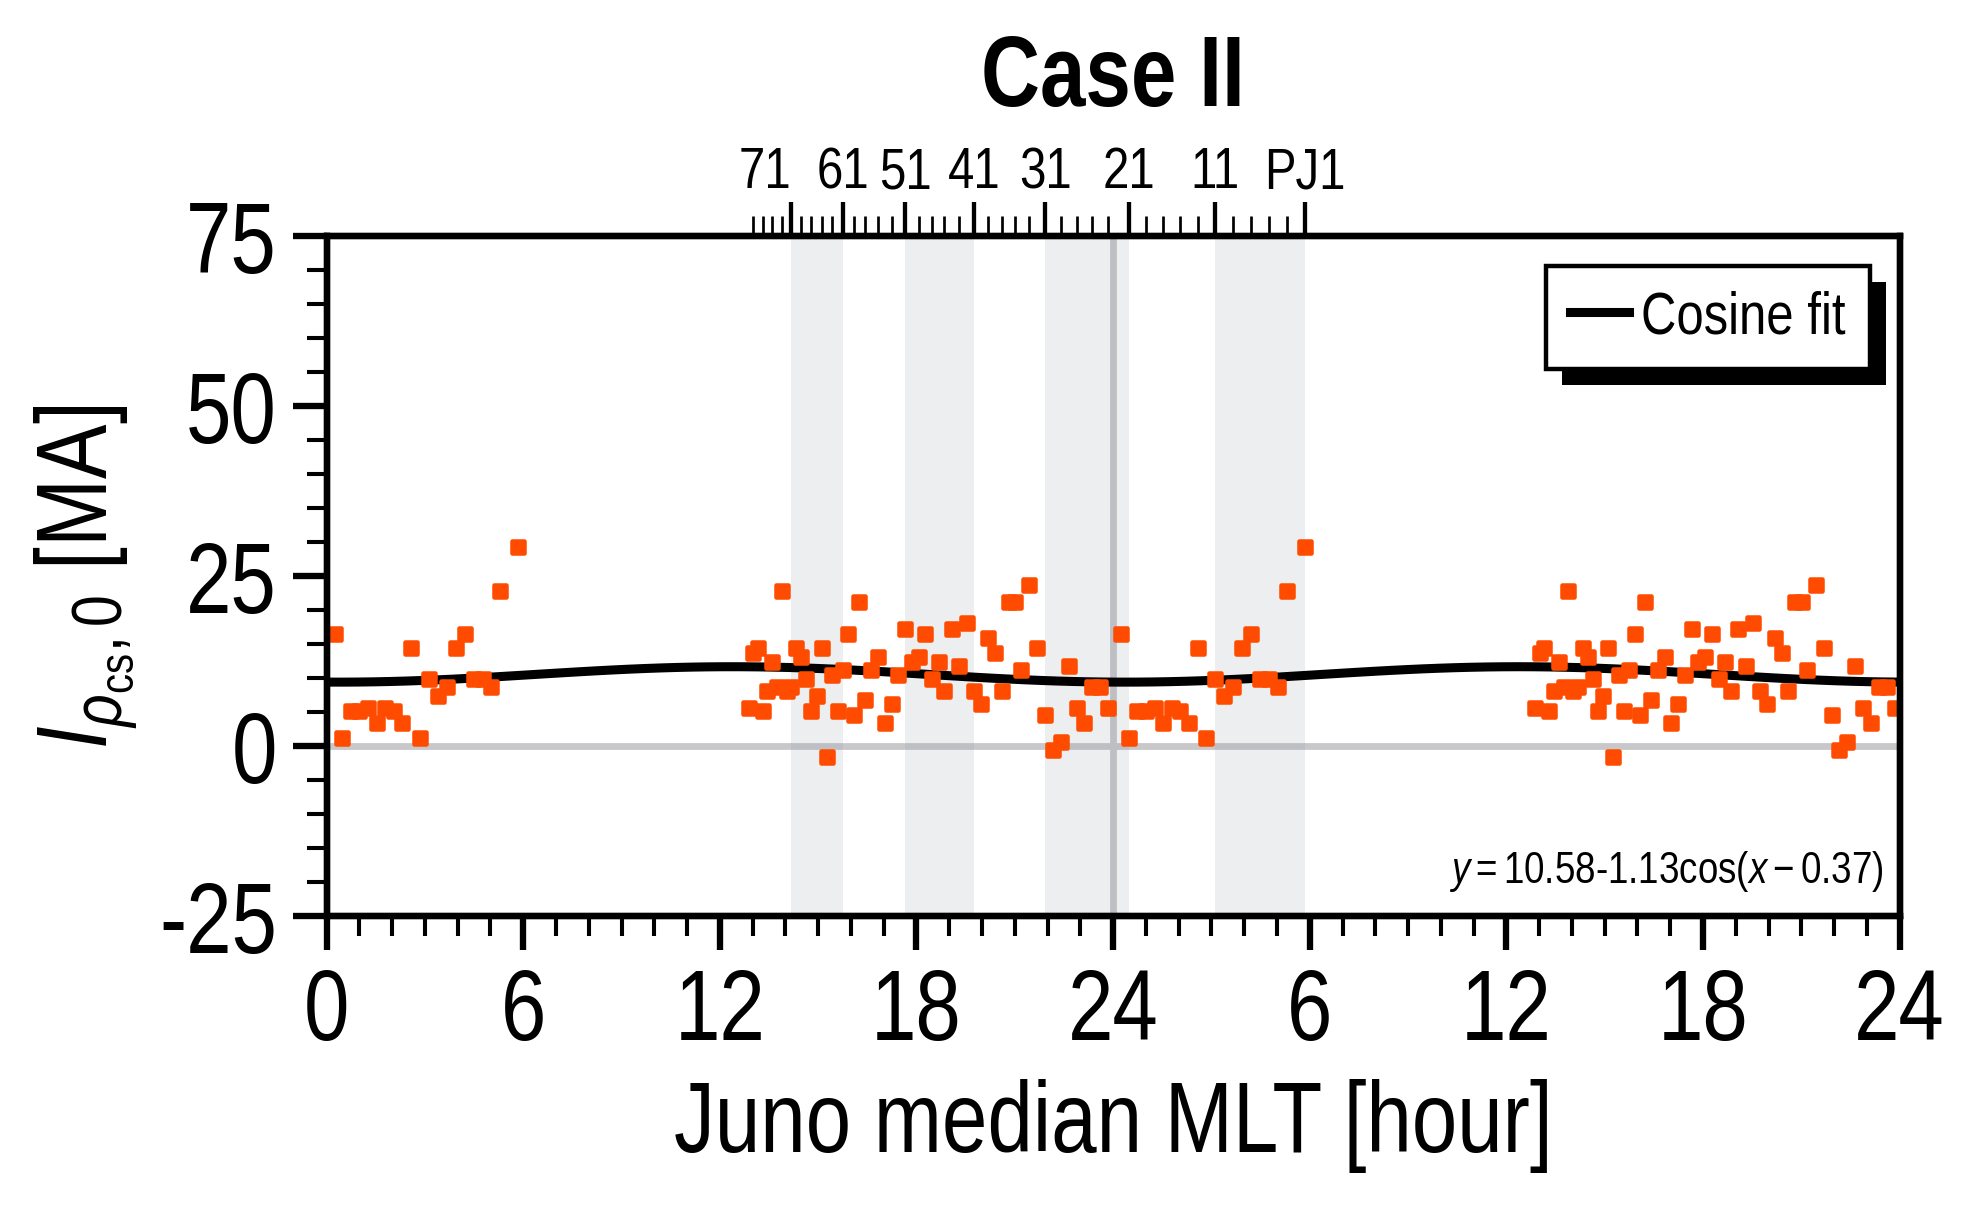

In [14]:
def func(X, a0, a1, a2):  # 2次式近似
    """
    Args:
        X (_type_): MLT [hr]
        a0 (_type_): _description_
        a1 (_type_): _description_
        a2 (_type_): _description_
    """
    MLT_rad = 2*np.pi*(X-a2)/24.0
    Y = a0 + a1*np.cos(MLT_rad)
    return Y


F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(6.3, 3.3), dpi='XL')
F.hspace = 0.18
F.initialize()

xticks = np.arange(0, 48+1, 6)
xticklabels = np.arange(0, 48+1, 6, dtype=int)
xticklabels[5:] += -24

F.set_xaxis(label=r'Juno median MLT [hour]',
            min=0.0, max=48.0,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=6)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=75,
            ticks=np.arange(-25, 75+1, 25),
            ticklabels=np.arange(-25, 75+1, 25),
            minor_num=5,)

for i in range(2):
    F.ax.scatter(f0[:, 6]+24.0*i, f0[:, 3],
                 s=6.0, marker='s', color=UC.red)

# I_rho0を三角関数でフィッティング
I_rho0 = f0[np.argsort(f0[:, 6]), 3]
Juno_MLT_arr = np.sort(f0[:, 6])
popt_I_rho0, _ = curve_fit(func, Juno_MLT_arr, I_rho0)  # poptは最適推定値、pcovは共分散
MLT_arr = np.linspace(0.0, 48.0, 100)
I_rho0_fit = func(MLT_arr, popt_I_rho0[0], popt_I_rho0[1], popt_I_rho0[2])
F.ax.plot(MLT_arr, I_rho0_fit, color='k',
          linewidth=2.0, label='Cosine fit', zorder=0.9)
y_fit_label = r'$y=$' + \
    str(round(popt_I_rho0[0], 2)) + str(round(popt_I_rho0[1], 2)) + \
    r'cos$(x-$' + str(round(np.mod(popt_I_rho0[2], 24.0), 2)) + '$)$'
F.ax.text(0.99, 0.1,
          y_fit_label,
          color='k',
          fontsize=F.fontsize*0.45,
          verticalalignment='top',
          horizontalalignment='right',
          transform=F.ax.transAxes)
print(popt_I_rho0)

F.ax.axhline(y=0, color=UC.lightgray, zorder=0.5)
F.ax.axvline(x=24.0, color=UC.lightgray, zorder=0.5)

# MLT vs PJ
PJ_mlt = np.zeros(80)
for i in range(80):
    if i == 1:
        PJ_mlt[i] = 0.5*(f0[0, 6]+f0[1, 6])+24.0
        continue
    elif i > 21:
        PJ_mlt[i] = f0[i-1, 6]
    elif i == 0:
        PJ_mlt[i] = f0[i, 6]+24.0
    else:
        PJ_mlt[i] = f0[i-1, 6]+24.0
PJax = F.ax.twiny()
PJax.set_xlim(0.0, 48.0)
PJax.set_xticks(PJ_mlt[::10])
PJax.set_xticklabels(JUNO_PJ_LABELS[:-1][::10], fontsize=F.fontsize*0.58)
PJax.xaxis.set_minor_locator(FixedLocator(PJ_mlt[::2]))
PJax.tick_params(which='major', width=0.95)
PJax.tick_params(which='minor', width=0.60)
for i, label in enumerate(PJax.get_xticklabels()):
    label.set_transform(
        label.get_transform() +
        plt.matplotlib.transforms.ScaledTranslation(
            0, -3 / 72,
            F.fig.dpi_scale_trans
        )
    )
ticklabels = PJax.get_xticklabels()
ticklabels[-1].set_ha('right')
PJax.set_xticklabels(ticklabels)

# Shades in each 10 perijove
for j in range(4):
    F.ax.axvspan(PJ_mlt[20*j], PJ_mlt[10+20*j],
                 fc=UC.gray, ec=None, zorder=0.5, alpha=0.15)


F.ax.set_title(case, weight='bold')

legend = F.legend(ax_idx=0, loc='upper right',
                  ncol=3, markerscale=3.5,
                  fontsize_scale=0.6, textcolor=False, handletextpad=0.2)
legend_shadow(fig=F.fig, ax=F.ax, legend=legend, d=1.0)

plt.savefig('img/'+dir[8:]+'_MLT_fit_003.pdf', bbox_inches='tight')

Correlation coef: 0.2895262339205745
p value: 0.009652587125184695


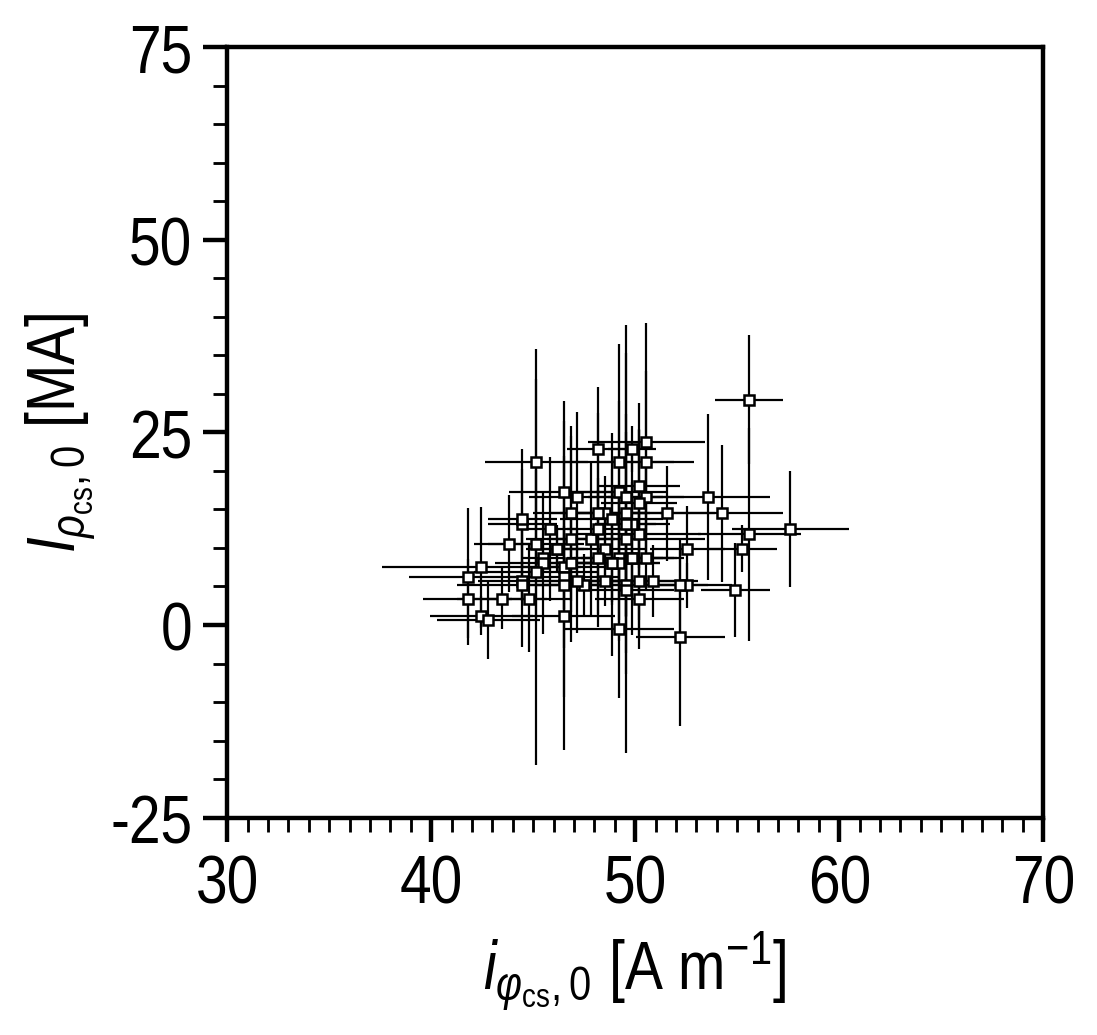

In [15]:
# %% ==================================
# 横軸: i_phi0 / 縦軸: I_rho0
# =====================================
i_phi0 = f0[:, 1]*1E+6
I_rho0 = f0[:, 3]
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.0, 4.6), dpi='L')
F.hspace = 0.15
F.initialize()

F.set_xaxis(label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=75,
            ticks=np.arange(-25, 75+1, 25),
            ticklabels=np.arange(-25, 75+1, 25),
            minor_num=5,)

"""F.ax.plot(i_phi0, I_rho0,
          marker='s', color=UC.red, markersize=3.5,
          linewidth=0.0, markeredgecolor='k', markerfacecolor='w',
          zorder=2)"""

F.ax.errorbar(x=f0[:, 1]*1E+6, y=f0[:, 3],
              xerr=f0[:, 2]*1E+6,
              yerr=f0[:, 4], color='k',
              elinewidth=0.7, linewidth=0.,
              marker='s', markersize=2.9,
              markeredgecolor='k', markerfacecolor='w',
              markeredgewidth=0.8,
              zorder=4)

coef, p_value = stats.pearsonr(i_phi0, I_rho0)
print('Correlation coef:', coef)
print('p value:', p_value)

Correlation coef: 0.2895262339205745
p value: 0.009652587125184695
XCC: [[1.         0.28952623]
 [0.28952623 1.        ]]


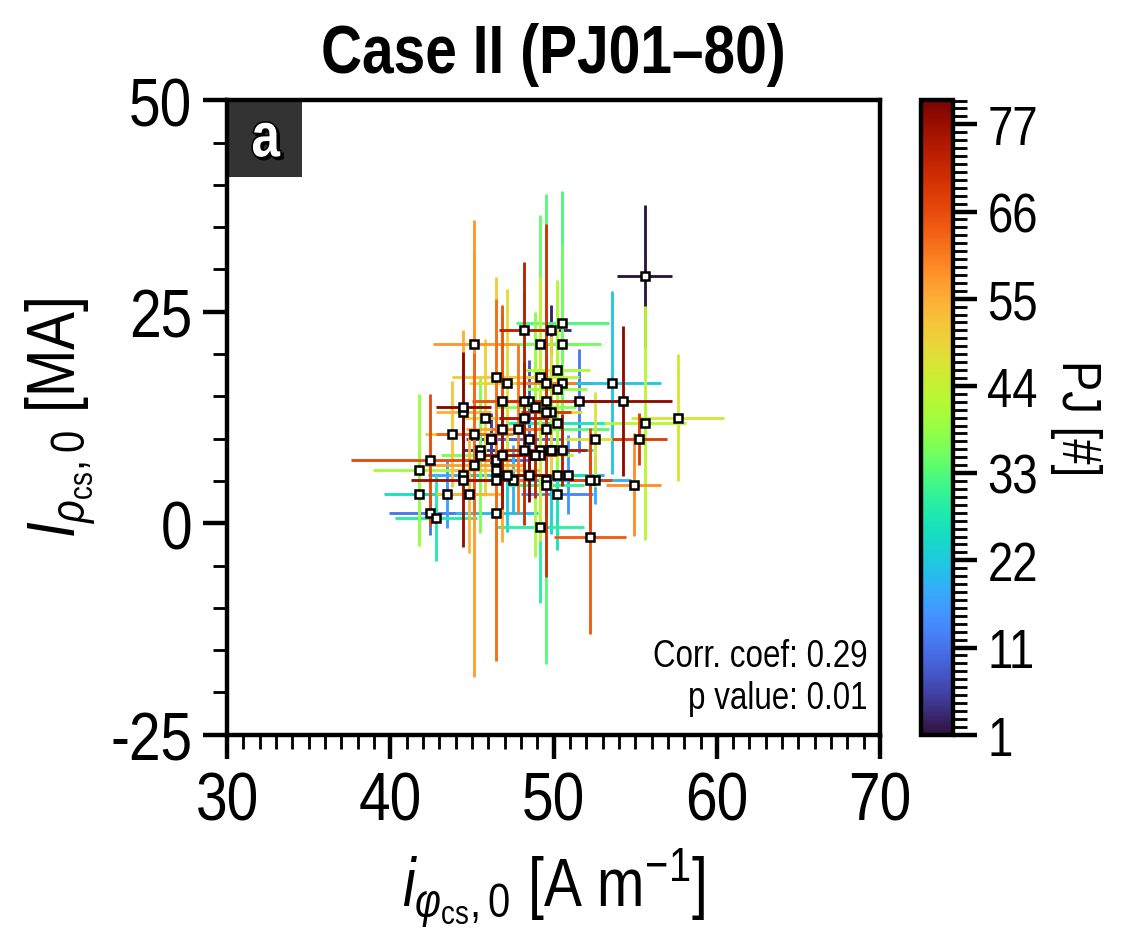

In [24]:
# %% ==================================
# 横軸: i_phi0 / 縦軸: I_rho0
# =====================================
i_phi0 = f0[:, 1]*1E+6
I_rho0 = f0[:, 3]
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.0, 4.0), dpi='L')
F.hspace = 0.15
F.initialize()

F.set_xaxis(label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=50,
            ticks=np.arange(-25, 50+1, 25),
            ticklabels=np.arange(-25, 50+1, 25),
            minor_num=5,)

vmin = 1.0
vmax = 80.0
cmap = plt.get_cmap('turbo')
norm = mplcolors.Normalize(vmin=vmin, vmax=vmax)

sc = F.ax.scatter(-99.0, -99.0, c=f0[i, 0],
                  vmin=vmin, vmax=vmax, cmap=cmap)
for i in range(f0[:, 1].size):
    F.ax.errorbar(x=f0[i, 1]*1E+6, y=f0[i, 3],
                  xerr=f0[i, 2]*1E+6,
                  yerr=f0[i, 4], color=cmap(norm(f0[i, 0])),
                  elinewidth=0.9, linewidth=0.,
                  marker='s', markersize=2.8,
                  markeredgecolor='k',
                  markerfacecolor='w',
                  markeredgewidth=0.8,
                  zorder=4)

# Normal correlation coefficient
coef, p_value = stats.pearsonr(f0[:, 1]*1E+6, f0[:, 3])
print('Correlation coef:', coef)
print('p value:', p_value)

# Cross correlation coefficient
print('XCC:', np.corrcoef(f0[:, 1]*1E+6, f0[:, 3]))

F.ax.text(0.98, 0.03,
          r'Corr. coef: '+str(round(coef, 3))+'\n' +
          r'p value: '+str(round(p_value, 3)),
          color='k',
          fontsize=F.fontsize*0.55,
          verticalalignment='bottom',
          horizontalalignment='right',
          transform=F.ax.transAxes)

F.draw_panel_name(ax=F.ax, panelname=' a ')

F.ax.set_title(case+' (PJ01–80)', weight='bold')

cax = F.fig.colorbar(sc, ax=F.ax)
cax.ax.set_yticks(np.linspace(1, 77, 8))
cax.ax.set_yticklabels(np.linspace(
    1, 77, 8, dtype=int), fontsize=F.fontsize*0.8)
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(11))
cax.ax.set_ylabel(r'PJ [#]',
                  verticalalignment='bottom',
                  rotation=270,
                  fontsize=F.fontsize*0.8)

plt.savefig('img/'+dir[8:]+'_MLT_fit_004.pdf', bbox_inches='tight')

Correlation coef: 0.5965727919928918
p value: 0.00039681885040938653
a_min_Irho, t_min_Irho, y_min_Irho, sigma_Irho:  0.019258523039176786 25.76062423390886 4.987624734063933 7.639112596864593 1.4904589204916068
a_min_iphi, t_min_iphi, y_min_iphi, sigma_iphi: 0.0036573033380681358 21.029028656577886 47.94516432942085 14.660966135005488


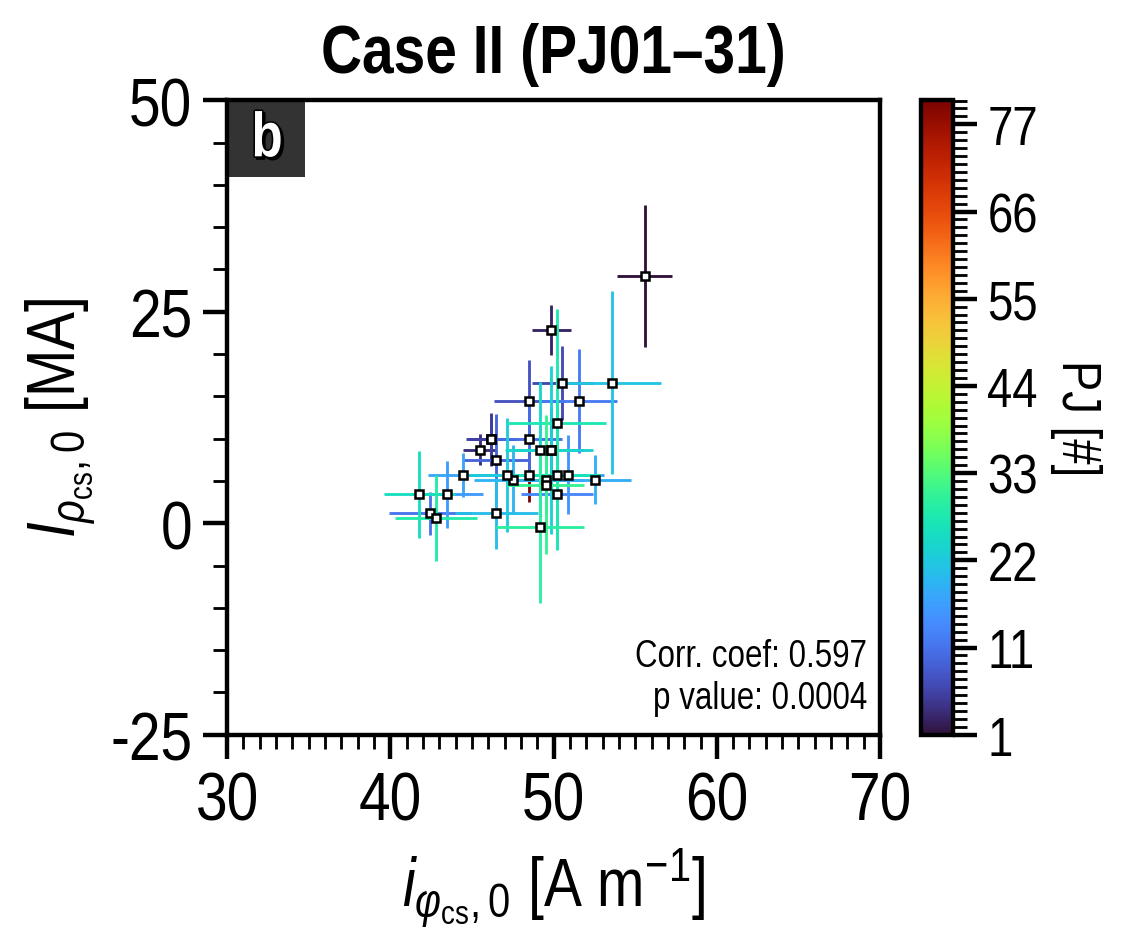

In [25]:
# %% ==================================
# 横軸: i_phi0 / 縦軸: I_rho0
# =====================================
def parabola(t, a, t_min, y_min):
    return a * (t - t_min)**2 + y_min


i_phi0 = f0[:, 1]*1E+6
I_rho0 = f0[:, 3]
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.0, 4.0), dpi='L')
F.hspace = 0.15
F.initialize()

F.set_xaxis(label=r'$i_{\varphi_{\rm cs},0}$ [A m$^{-1}$]',
            min=30.0, max=70.0,
            ticks=np.arange(30, 70+1, 10),
            ticklabels=np.arange(30, 70+1, 10, dtype=int),
            minor_num=10,)
F.set_yaxis(ax_idx=1,
            label=r'$I_{\rho_{\rm cs}, 0}$ [MA]',
            min=-25, max=50,
            ticks=np.arange(-25, 50+1, 25),
            ticklabels=np.arange(-25, 50+1, 25),
            minor_num=5,)

vmin = 1.0
vmax = 80.0
cmap = plt.get_cmap('turbo')
norm = mplcolors.Normalize(vmin=vmin, vmax=vmax)

sc = F.ax.scatter(-99.0, -99.0, c=f0[2, 0],
                  vmin=vmin, vmax=vmax, cmap=cmap)
start_pj = 1
end_pj = 32
PJ_number_slice = []
x_data_slice = []
y_data_slice = []
for i in range(f0[start_pj:end_pj, 1].size):
    i += start_pj
    if i not in [80]:
        PJ_number_slice += [i]
        x_data_slice += [f0[i-2, 1]*1E+6]
        y_data_slice += [f0[i-2, 3]]
        F.ax.errorbar(x=f0[i-2, 1]*1E+6, y=f0[i-2, 3],
                      xerr=f0[i-2, 2]*1E+6,
                      yerr=f0[i-2, 4], color=cmap(norm(f0[i-2, 0])),
                      elinewidth=0.9, linewidth=0.,
                      marker='s', markersize=2.8,
                      markeredgecolor='k',
                      markerfacecolor='w',
                      markeredgewidth=0.8,
                      zorder=4)

# Normal correlation coefficient
coef, p_value = stats.pearsonr(
    x_data_slice, y_data_slice)
print('Correlation coef:', coef)
print('p value:', p_value)

# 2次関数フィッティング
popt_iphi, pcov_iphi = curve_fit(
    parabola, PJ_number_slice, x_data_slice, p0=[1, 55, 45.0])
popt_Irho, pcov_Irho = curve_fit(
    parabola, PJ_number_slice, y_data_slice, p0=[1, 55, 0])
a_min_Irho = popt_Irho[0]
a_min_iphi = popt_iphi[0]
t_min_Irho = popt_Irho[1]
t_min_iphi = popt_iphi[1]
y_min_Irho = popt_Irho[2]
y_min_iphi = popt_iphi[2]
sigma_Irho = np.sqrt(pcov_Irho[1, 1])
sigma_iphi = np.sqrt(pcov_iphi[1, 1])
print('a_min_Irho, t_min_Irho, y_min_Irho, sigma_Irho: ',
      a_min_Irho, t_min_Irho, y_min_Irho, sigma_Irho, np.sqrt(pcov_Irho[2, 2]))
print('a_min_iphi, t_min_iphi, y_min_iphi, sigma_iphi:',
      a_min_iphi, t_min_iphi, y_min_iphi, sigma_iphi)

F.ax.text(0.98, 0.03,
          r'Corr. coef: '+str(round(coef, 3))+'\n' +
          r'p value: '+str(round(p_value, 4)),
          color='k',
          fontsize=F.fontsize*0.55,
          verticalalignment='bottom',
          horizontalalignment='right',
          transform=F.ax.transAxes,
          zorder=5)

F.draw_panel_name(ax=F.ax, panelname=' b ')

F.ax.set_title(case+' (PJ'+str(start_pj).zfill(2)+'–' +
               str(end_pj-1).zfill(2)+')', weight='bold')

cax = F.fig.colorbar(sc, ax=F.ax)
cax.ax.set_yticks(np.linspace(1, 77, 8))
cax.ax.set_yticklabels(np.linspace(
    1, 77, 8, dtype=int), fontsize=F.fontsize*0.8)
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(11))
cax.ax.set_ylabel(r'PJ [#]',
                  verticalalignment='bottom',
                  rotation=270,
                  fontsize=F.fontsize*0.8)

plt.savefig('img/'+dir[8:]+'_MLT_fit_005.pdf', bbox_inches='tight')